# Fase 2A · v2 — Machine Learning: LR, RF, XGBoost, Hard y Soft Voting (IroSvA)

**Nested CV 5×3 agrupada · TF-IDF ≤10k · F1-Macro + calibración (NLL, ECE, Brier)**

Esta versión aplica a los modelos clásicos la misma lógica que la v6 de los Transformers: **medir la brecha train–validación, regularizar con una regla fijada de antemano y calibrar con predicciones out-of-fold del train**. El protocolo de datos no cambia: mismos CSV, mismos grupos (Union-Find), mismas semillas y, por tanto, **los mismos Outer/Inner folds que la v1**, lo que permite comparar v1 → v2 fold a fold.

| Aspecto | v1 (`ML_TFIDF_10k_..._CORREGIDO` + `ML_HardVoting_...`) | v2 (este notebook) |
|---|---|---|
| Búsqueda LR / RF | `GridSearchCV` | `GridSearchCV` (se mantiene) |
| Rejilla LR | `C ∈ {0.1, 1, 10}`, L2 | `C`: 9 valores log de 0.01 a 100; L1 o L2; `min_df ∈ {1,2,3}`; `sublinear_tf ∈ {F,T}`; n-gramas |
| Rejilla RF | `n_estimators`, `max_depth`, `min_samples_split` | `n_estimators=500` fijo; `max_features ∈ {sqrt, log2, 0.03}`; `min_samples_leaf ∈ {1,2,5,10}`; `min_df ∈ {1,3}`; n-gramas |
| XGBoost | Optuna TPE, 50 trials | Igual, y además busca `min_df` y `sublinear_tf` |
| 9 rasgos lingüísticos | `passthrough` (sin escalar) | `StandardScaler` (ajustado dentro de cada fold) |
| Selección LR / RF | máximo F1 interno | **regla**: la regularización más fuerte a ≤ 0.01 del mejor F1 interno (se guarda también el máximo) |
| Métricas | F1, brecha | F1, brecha, **NLL, ECE (bins de igual masa), Brier** |
| Ensemble | Hard Voting (sin probabilidades) | **Hard Voting y Soft Voting** (promedio de probabilidades) |
| Calibración | — | **Temperature scaling** con probabilidades OOF del train, aplicado al test |

**Por qué se mantiene la rejilla en LR y RF.** Con pocos hiperparámetros y modelos baratos, la búsqueda exhaustiva es adecuada; la ventaja de la búsqueda aleatoria o bayesiana aparece en espacios de alta dimensión (Bergstra & Bengio, 2012). En RF, `max_features` y `min_samples_leaf` son los hiperparámetros con más efecto, y el número de árboles no se afina sino que se fija alto (Probst, Wright & Boulesteix, 2019; Probst & Boulesteix, 2018). LR depende casi solo de `C` (Probst, Boulesteix & Bischl, 2019). TPE se reserva para XGBoost y los Transformers.

Los resultados se escriben en `../data/resultados_ml_grouped_5x3_grid_v2/`. La v1 se lee solo para comparar; no se modifica.

## 1. Librerías y entorno

In [2]:
import os
import json
import time
import html
import copy
import warnings
from datetime import datetime
from pathlib import Path

# Silencia avisos de convergencia/stopwords también en los procesos paralelos de joblib.
os.environ.setdefault("PYTHONWARNINGS", "ignore")
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import optuna
import scipy
import sklearn
import xgboost
import nltk
import matplotlib.pyplot as plt
from scipy import stats
from nltk.corpus import stopwords
from IPython.display import display, HTML

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_score
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
)
from xgboost import XGBClassifier

try:
    STOP_WORDS = stopwords.words("spanish")
except LookupError:
    if not nltk.download("stopwords", quiet=True):
        raise RuntimeError("Instala el corpus NLTK de stopwords para reproducir el TF-IDF original.")
    STOP_WORDS = stopwords.words("spanish")

optuna.logging.set_verbosity(optuna.logging.WARNING)

VERSIONES = {
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "sklearn": sklearn.__version__,
    "xgboost": xgboost.__version__,
    "optuna": optuna.__version__,
}
print("Versiones:", " | ".join(f"{k} {v}" for k, v in VERSIONES.items()))
if tuple(int(x) for x in sklearn.__version__.split(".")[:2]) < (1, 8):
    raise RuntimeError("Este notebook usa `l1_ratio` de LogisticRegression (scikit-learn >= 1.8).")

Versiones: numpy 1.26.4 | pandas 3.0.3 | scipy 1.13.1 | sklearn 1.8.0 | xgboost 3.2.0 | optuna 5.0.0


## 2. Configuración

Todo lo que define el experimento está en esta celda: modo, rejillas, regla de selección y bloqueo del test.

- `MODO="prueba"`: valida el pipeline completo en minutos (solo MX, Nested 2×2, rejillas reducidas y 4 trials de XGBoost). Escribe en `…/resultados_ml_grouped_5x3_grid_v2/prueba/`.
- `MODO="completo"`: experimento definitivo 5×3.

**Regla de selección (`REGLA_TOLERANCIA = 0.01`).** Es la misma regla de los pilotos v5b de los Transformers, fijada antes de ver resultados: *entre todas las combinaciones cuyo F1 interno queda a ≤ 0.01 del mejor, se elige la de regularización más fuerte*. En LR, «más fuerte» = menor `C`; en RF, mayor `min_samples_leaf`. Los empates se resuelven por mayor F1 interno. Es la misma idea que la regla de «un error estándar» de CART (Breiman et al., 1984), con una tolerancia fija. Con `SELECCION_PRINCIPAL = "max"` se recupera el criterio clásico; **en ambos casos se evalúan las dos selecciones en cada Outer Fold**, para poder reportar el efecto de la regla. XGBoost usa siempre el máximo (su regularización está repartida en varios hiperparámetros y no admite un orden único).

El test oficial solo se ejecuta en modo completo, con `EJECUTAR_TEST_OFICIAL=True` y `CONFIRMACION_TEST="TEST_OFICIAL_CONGELADO"`.

In [3]:
DATA_DIR = Path("../data")
RANDOM_STATE = 42
MODELOS = ["LR", "RF", "XGBoost"]
MODELOS_LR_RF = ["LR", "RF"]
MODELOS_VOTING = ["HardVoting", "SoftVoting"]
ORDEN_MODELOS = MODELOS + MODELOS_VOTING
PREPROCESAMIENTOS = {"normal": "", "stem": "_stem", "lemma": "_lemma"}
FEATURE_COLS = ["n_exc", "n_int", "n_may", "n_emo", "n_ris", "n_neg", "n_elo", "n_com", "n_pun"]

# ------------------------------------------------------------
# "prueba" valida rápidamente todo el pipeline; "completo" = experimento definitivo 5×3.
# ------------------------------------------------------------
MODO = "completo"

if MODO == "prueba":
    VARIANTES = ["mx"]
    N_OUTER, N_INNER = 2, 2
    N_TRIALS_NESTED, N_TRIALS_FINAL = 4, 4
    REJILLA_REDUCIDA = True
elif MODO == "completo":
    VARIANTES = ["mx", "es", "cu"]
    N_OUTER, N_INNER = 5, 3
    N_TRIALS_NESTED, N_TRIALS_FINAL = 50, 50
    REJILLA_REDUCIDA = False
else:
    raise ValueError("MODO debe ser 'prueba' o 'completo'.")

OUT_DIR = DATA_DIR / "resultados_ml_grouped_5x3_grid_v2"
# v1, solo lectura (para la comparación v1 → v2).
V1_DIR = DATA_DIR / "resultados_ml_groupcv_tfidf_lr_rf_10k"
V1_HV_DIR = DATA_DIR / "resultados_ml_hard_voting_tfidf10k"
if MODO == "prueba":
    OUT_DIR, V1_DIR, V1_HV_DIR = OUT_DIR / "prueba", V1_DIR / "prueba", V1_HV_DIR / "prueba"
MODELS_DIR = OUT_DIR / "modelos_finales"
for carpeta in [OUT_DIR, MODELS_DIR]:
    carpeta.mkdir(parents=True, exist_ok=True)

N_JOBS_GRID = -1  # paralelismo de GridSearchCV (LR/RF)
N_JOBS_XGB = -1   # hilos dentro de XGBoost; la CV de Optuna es secuencial

# ---------------- TF-IDF ----------------
MAX_FEATURES_TFIDF = 10000
NGRAMAS_OPCIONES = {"uni": (1, 1), "uni_bi": (1, 2)}
MIN_DF_XGB = [1, 2, 3]
SUBLINEAR_XGB = [False, True]

# ---------------- Rejillas LR / RF ----------------
# LR: l1_ratio=0 → L2, l1_ratio=1 → L1 (en sklearn 1.8 `penalty` está obsoleto).
RF_N_ESTIMATORS = 500
if not REJILLA_REDUCIDA:
    GRID_LR = {
        "clf__C": [float(c) for c in np.logspace(-2, 2, 9).round(4)],
        "clf__l1_ratio": [0.0, 1.0],
        "features__tfidf__min_df": [1, 2, 3],
        "features__tfidf__sublinear_tf": [False, True],
        "features__tfidf__ngram_range": [(1, 1), (1, 2)],
    }
    GRID_RF = {
        "clf__max_features": ["sqrt", "log2", 0.03],
        "clf__min_samples_leaf": [1, 2, 5, 10],
        "features__tfidf__min_df": [1, 3],
        "features__tfidf__ngram_range": [(1, 1), (1, 2)],
    }
else:
    RF_N_ESTIMATORS = 100
    GRID_LR = {
        "clf__C": [0.1, 1.0, 10.0],
        "clf__l1_ratio": [0.0],
        "features__tfidf__min_df": [1, 2],
        "features__tfidf__sublinear_tf": [False, True],
        "features__tfidf__ngram_range": [(1, 1)],
    }
    GRID_RF = {
        "clf__max_features": ["sqrt"],
        "clf__min_samples_leaf": [1, 5],
        "features__tfidf__min_df": [1],
        "features__tfidf__ngram_range": [(1, 1)],
    }

# ---------------- Regla de selección ----------------
REGLA_TOLERANCIA = 0.01          # None → solo máximo F1
SELECCION_PRINCIPAL = "regla"    # "regla" | "max"
# Hiperparámetro que define "más regularizado": (clave, "asc" = menor es más fuerte | "desc").
REGULARIZADOR = {"LR": ("clf__C", "asc"), "RF": ("clf__min_samples_leaf", "desc")}

# ---------------- Calibración ----------------
GRILLA_T = np.exp(np.linspace(np.log(0.05), np.log(8.0), 500))  # contiene la grilla de la v6 (0.25–8); RF suele necesitar T < 0.25

# ---------------- Test oficial ----------------
EJECUTAR_TEST_OFICIAL = False
CONFIRMACION_TEST = ""

n_lr = int(np.prod([len(v) for v in GRID_LR.values()]))
n_rf = int(np.prod([len(v) for v in GRID_RF.values()]))
print(f"[CONFIG][ML v2] modo={MODO} | variantes={VARIANTES} | Nested={N_OUTER}×{N_INNER}")
print(f"[CONFIG][ML v2] rejilla LR={n_lr} comb. | rejilla RF={n_rf} comb. (×3 preprocesamientos)")
print(f"[CONFIG][ML v2] XGBoost trials={N_TRIALS_NESTED} por Outer (final={N_TRIALS_FINAL})")
print(f"[CONFIG][ML v2] selección principal={SELECCION_PRINCIPAL} | tolerancia={REGLA_TOLERANCIA}")
print(f"[CONFIG][ML v2] test oficial={EJECUTAR_TEST_OFICIAL} | OUT_DIR={OUT_DIR.resolve()}")

# Seguimiento: panel de progreso común a todos los notebooks de modelos.
NOMBRE_EXPERIMENTO = "ML v2"
HEARTBEAT_SEGUNDOS = 30
AVISO_SONORO = True  # pitido de Windows al terminar/detenerse una etapa larga


class Monitor:
    """Panel único de progreso + monitor.log, con estado activo / terminado / error.

    Clase común a todos los notebooks de modelos (ML, Hard Voting y Transformers).
    """

    def __init__(self, ruta, total, ya_completados=0, unidad="Fine-tunings completados"):
        self.ruta = Path(ruta)
        self.ruta.mkdir(parents=True, exist_ok=True)
        self.log = self.ruta / "monitor.log"
        self.total = int(total)
        self.unidad = unidad
        self.completados = int(ya_completados)
        self.completados_inicio = int(ya_completados)
        self.inicio = time.monotonic()
        self.ultimo_pulso = 0
        self.etapa = "Inicializando"
        self.estado = "activo"  # activo | terminado | error
        self.handle = display(HTML(f"<b>Preparando {NOMBRE_EXPERIMENTO}...</b>"), display_id=True)
        self.mostrar(forzar=True)

    def registrar(self, msg):
        with self.log.open("a", encoding="utf-8") as f:
            f.write(f"[{datetime.now():%Y-%m-%d %H:%M:%S}] {msg}\n")

    def mostrar(self, etapa=None, forzar=False):
        if etapa is not None:
            self.etapa = str(etapa)
        ahora = time.monotonic()
        if not forzar and ahora - self.ultimo_pulso < HEARTBEAT_SEGUNDOS:
            return
        self.ultimo_pulso = ahora
        minutos = (ahora - self.inicio) / 60
        hechos_sesion = self.completados - self.completados_inicio
        faltan = max(0, self.total - self.completados)
        eta = (
            f"~{minutos / hechos_sesion * faltan:.0f} min"
            if hechos_sesion >= 2
            else "calculando..."
        )
        marca = datetime.now().strftime("%H:%M:%S")
        color, titulo = {
            "activo": ("#777", f"{NOMBRE_EXPERIMENTO} — seguimiento en vivo"),
            "terminado": ("#2e7d32", f"✅ {NOMBRE_EXPERIMENTO} — TERMINADO"),
            "error": ("#c62828", f"❌ {NOMBRE_EXPERIMENTO} — DETENIDO"),
        }[self.estado]
        grosor = 1 if self.estado == "activo" else 3
        tiempo = (
            f"Tiempo: {minutos:.1f} min | ETA orientativo: {eta}"
            if self.estado == "activo"
            else f"Duración total: {minutos:.1f} min | Finalizó a las {marca}"
        )
        panel = (
            f'<div style="font-family:system-ui;padding:12px;border:{grosor}px solid {color};'
            'border-radius:8px;max-width:800px">'
            f'<b style="color:{color}">{titulo}</b><br>'
            f"Etapa: <b>{html.escape(self.etapa)}</b><br>"
            f"{self.unidad}: {self.completados}/{self.total} "
            f"({100*self.completados/max(1,self.total):.1f}%)<br>"
            f'<progress value="{self.completados}" max="{max(1,self.total)}" '
            'style="width:100%"></progress><br>'
            f"{tiempo}<br>"
            f"Última señal: {marca}<br>Log: {html.escape(str(self.log))}</div>"
        )
        self.handle.update(HTML(panel))

    def iniciar(self, msg):
        self.registrar(msg)
        self.mostrar(etapa=msg, forzar=True)

    def pulso(self):
        if time.monotonic() - self.ultimo_pulso >= HEARTBEAT_SEGUNDOS:
            self.registrar("ACTIVO: " + self.etapa)
            self.mostrar(forzar=True)

    def fit_terminado(self, msg):
        self.completados += 1
        self.registrar(msg)
        self.mostrar(etapa=msg, forzar=True)

    def finalizar(self, msg):
        """Etapa terminada: panel verde al 100 %, mensaje en la celda y aviso sonoro."""
        self.registrar(f"FINALIZADO: {msg} ({self.completados}/{self.total} contados)")
        self.estado = "terminado"
        self.completados = max(self.completados, self.total)
        self.mostrar(etapa=msg, forzar=True)
        print(f"\n✅ [{NOMBRE_EXPERIMENTO}] {msg} — {datetime.now():%Y-%m-%d %H:%M:%S}", flush=True)
        avisar_fin(ok=True)

    def fallar(self, msg):
        """Etapa detenida (error o interrupción): panel rojo, mensaje en la celda y aviso sonoro."""
        self.registrar(f"DETENIDO: {msg}")
        self.estado = "error"
        self.mostrar(etapa=msg, forzar=True)
        print(f"\n❌ [{NOMBRE_EXPERIMENTO}] {msg} — {datetime.now():%Y-%m-%d %H:%M:%S}", flush=True)
        avisar_fin(ok=False)


def avisar_fin(ok=True):
    """Pitido de Windows al terminar (3 veces) o al detenerse (1 vez); en otros sistemas no hace nada."""
    if not AVISO_SONORO:
        return
    try:
        import winsound

        for _ in range(3 if ok else 1):
            winsound.MessageBeep(winsound.MB_ICONASTERISK if ok else winsound.MB_ICONHAND)
            time.sleep(0.5)
    except Exception:
        pass

[CONFIG][ML v2] modo=completo | variantes=['mx', 'es', 'cu'] | Nested=5×3
[CONFIG][ML v2] rejilla LR=216 comb. | rejilla RF=48 comb. (×3 preprocesamientos)
[CONFIG][ML v2] XGBoost trials=50 por Outer (final=50)
[CONFIG][ML v2] selección principal=regla | tolerancia=0.01
[CONFIG][ML v2] test oficial=False | OUT_DIR=C:\Users\I21309\Documents\DeteccionDeSarcasmo\data\resultados_ml_grouped_5x3_grid_v2


## 3. Integridad de los CSV y validación por grupos

Celda idéntica a la de la v1: misma verificación de alineación `normal/stem/lemma`, mismos grupos por componentes conexos (Union-Find) y mismos splits `StratifiedGroupKFold`. Al mantener semillas y grupos, los Outer Folds son **exactamente los mismos** que en la v1 y en los Transformers.

In [4]:
# ============================================================
# 3. CARGA, INTEGRIDAD Y GRUPOS SIN FUGA ENTRE FOLDS
# ============================================================
GRUPOS_TRAIN = {}  # Variante -> np.array; solo contiene información del TRAIN
AUDITORIA_GRUPOS = []
AUDITORIA_CONFLICTOS = []
AUDITORIA_PARTICIONES = []


class UnionFind:
    """Componentes conexos: unión por rango con compresión de caminos."""

    def __init__(self, n):
        self.parent = list(range(n))
        self.rank = [0] * n

    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return
        if self.rank[ra] < self.rank[rb]:
            ra, rb = rb, ra
        self.parent[rb] = ra
        if self.rank[ra] == self.rank[rb]:
            self.rank[ra] += 1


def cargar_split(variante, prep, split="train"):
    """Carga el CSV preprocesado de una variante, representación y split."""
    if variante not in VARIANTES or prep not in PREPROCESAMIENTOS:
        raise ValueError(f"Variante/preprocessing no reconocido: {variante}/{prep}")
    ruta = DATA_DIR / f"{split}_clean{PREPROCESAMIENTOS[prep]}_{variante}.csv"
    if not Path(ruta).is_file():
        raise FileNotFoundError(f"Falta el CSV: {ruta}")
    # Preservar los IDs originales: no forzarles una conversión numérica.
    return pd.read_csv(ruta, dtype={"ID": "string"}).reset_index(drop=True)


def preparar_xy(df):
    """Separa texto + 9 rasgos (X) y etiqueta (y)."""
    columnas = ["MESSAGE_CLEAN"] + FEATURE_COLS
    faltantes = [c for c in columnas + ["IS_IRONIC"] if c not in df.columns]
    if faltantes:
        raise ValueError(f"Faltan columnas requeridas: {faltantes}")
    X = df[columnas].copy()
    y = df["IS_IRONIC"].astype(int).reset_index(drop=True)
    X["MESSAGE_CLEAN"] = X["MESSAGE_CLEAN"].fillna("").astype(str)
    X[FEATURE_COLS] = X[FEATURE_COLS].fillna(0)
    return X.reset_index(drop=True), y


def texto_clave(serie):
    """Normalización usada solo para comparar textos al agrupar (no altera el texto del modelo)."""
    # Misma normalización de COMPARACIÓN que la auditoría previa; no modifica el texto del modelo.
    return serie.fillna("").astype(str).str.casefold().str.strip()


def construir_grupos(variante, dfs_por_prep, y):
    """Componentes conexos: agrupa un mismo texto tras normal, stem O lemma.
    No deduplica, no usa las etiquetas para construir grupos y conserva rasgos originales.
    Añade coincidencias de MESSAGE original exacto, si está disponible.
    """
    n = len(y)
    uf = UnionFind(n)

    for prep, df in dfs_por_prep.items():
        primero = {}
        for i, clave in enumerate(texto_clave(df["MESSAGE_CLEAN"])):
            if not clave:
                raise ValueError(
                    f"{variante}/{prep}: texto limpio vacío en fila {i}; revisar antes de agrupar"
                )
            if clave in primero:
                uf.union(primero[clave], i)
            else:
                primero[clave] = i
    # Si dos textos originales son idénticos, deben permanecer en el mismo grupo.
    df_ref = dfs_por_prep["normal"]
    if "MESSAGE" in df_ref:
        primero_raw = {}
        for i, clave in enumerate(texto_clave(df_ref["MESSAGE"])):
            if not clave:
                continue
            if clave in primero_raw:
                uf.union(primero_raw[clave], i)
            else:
                primero_raw[clave] = i

    miembros = {}
    for i in range(n):
        miembros.setdefault(uf.find(i), []).append(i)
    # Id de grupo basado en el menor índice original; determinista entre ambos notebooks.
    ids = {ra: min(idx) for ra, idx in miembros.items()}
    grupos = np.array([ids[uf.find(i)] for i in range(n)], dtype=int)
    duplicados = {ids[ra]: idx for ra, idx in miembros.items() if len(idx) > 1}
    conflictivos = [(g, idx) for g, idx in duplicados.items() if y.iloc[idx].nunique() > 1]
    if conflictivos:
        warnings.warn(
            f"{variante.upper()}: {len(conflictivos)} grupo(s) con etiquetas contradictorias. "
            "Se conservan las etiquetas originales y se mantienen juntos todos sus registros. "
            "Revisar manualmente antes de interpretar resultados.",
            stacklevel=2,
        )
    for g, idx in conflictivos:
        for i in idx:
            AUDITORIA_CONFLICTOS.append(
                {
                    "variante": variante,
                    "grupo": int(g),
                    "fila_0base": int(i),
                    "id_original": str(df_ref.iloc[i]["ID"]) if "ID" in df_ref else "",
                    "etiqueta": int(y.iloc[i]),
                    "texto_original": str(df_ref.iloc[i]["MESSAGE"]) if "MESSAGE" in df_ref else "",
                    "texto_normal": str(df_ref.iloc[i]["MESSAGE_CLEAN"]),
                }
            )
    AUDITORIA_GRUPOS.append(
        {
            "variante": variante,
            "n_train": n,
            "n_grupos": len(miembros),
            "n_grupos_multiples": len(duplicados),
            "n_filas_en_grupos_multiples": sum(map(len, duplicados.values())),
            "tamano_grupo_max": max(map(len, miembros.values())),
            "n_grupos_etiquetas_contradictorias": len(conflictivos),
            "criterio": "union_texto_normal_stem_lemma_y_original_exacto",
        }
    )
    return grupos


def cargar_todos_preps(variante, split="train"):
    """Carga normal/stem/lemma de una variante, verifica que estén alineados y construye los grupos."""
    dfs = {p: cargar_split(variante, p, split=split) for p in PREPROCESAMIENTOS}
    ref = dfs["normal"]
    X_ref, y_ref = preparar_xy(ref)
    datos = {"normal": X_ref}
    for prep, df in dfs.items():
        if prep == "normal":
            continue
        X, y = preparar_xy(df)
        if len(df) != len(ref) or not y.equals(y_ref):
            raise ValueError(f"{variante}/{prep}: diferente número de filas o etiquetas")
        for c in ["ID", "MESSAGE"]:
            if c in ref.columns and c not in df.columns:
                raise ValueError(f"{variante}/{prep}: falta columna de alineación {c}")
            if c in ref.columns and not ref[c].astype(str).equals(df[c].astype(str)):
                raise ValueError(f"{variante}/{prep}: columna {c} desalineada")
        if not X[FEATURE_COLS].equals(X_ref[FEATURE_COLS]):
            raise ValueError(f"{variante}/{prep}: rasgos lingüísticos no alineados")
        datos[prep] = X
    if split == "train" and variante not in GRUPOS_TRAIN:
        GRUPOS_TRAIN[variante] = construir_grupos(variante, dfs, y_ref)
    return datos, y_ref


def grupos_train(variante):
    """Devuelve los grupos del train de una variante (los construye si aún no existen)."""
    if variante not in GRUPOS_TRAIN:
        cargar_todos_preps(variante, split="train")
    return GRUPOS_TRAIN[variante]


def verificar_particion(grupos, a, b, variante, nivel, outer, inner=None):
    """Comprueba que train y validación no compartan grupos y registra la partición."""
    solapamiento = set(grupos[a]) & set(grupos[b])
    if solapamiento:
        raise AssertionError(
            f"FUGA: {variante}/{nivel}/{outer}/{inner} grupos compartidos: {solapamiento}"
        )
    AUDITORIA_PARTICIONES.append(
        {
            "variante": variante,
            "nivel": nivel,
            "outer_fold": outer,
            "inner_fold": inner,
            "n_train": len(a),
            "n_validacion": len(b),
            "n_grupos_compartidos": 0,
        }
    )


def crear_splits_outer(y, grupos, variante="?"):
    """Outer CV agrupada y estratificada."""
    cv = StratifiedGroupKFold(n_splits=N_OUTER, shuffle=True, random_state=RANDOM_STATE)
    splits = list(cv.split(np.zeros(len(y)), y, groups=grupos))
    for fold, (a, b) in enumerate(splits, 1):
        verificar_particion(grupos, a, b, variante, "outer", fold)
    return splits


def crear_splits_inner(y, grupos, outer_fold, variante="?"):
    """Inner CV agrupada dentro de un Outer Train (semilla RANDOM_STATE + outer_fold)."""
    cv = StratifiedGroupKFold(
        n_splits=N_INNER, shuffle=True, random_state=RANDOM_STATE + outer_fold
    )
    splits = list(cv.split(np.zeros(len(y)), y, groups=grupos))
    for fold, (a, b) in enumerate(splits, 1):
        verificar_particion(grupos, a, b, variante, "inner", outer_fold, fold)
    return splits


def crear_splits_final(y, grupos, variante="?"):
    """CV agrupada sobre todo el train para la búsqueda final."""
    cv = StratifiedGroupKFold(n_splits=N_INNER, shuffle=True, random_state=RANDOM_STATE)
    splits = list(cv.split(np.zeros(len(y)), y, groups=grupos))
    for fold, (a, b) in enumerate(splits, 1):
        verificar_particion(grupos, a, b, variante, "final", 0, fold)
    return splits


# ============================================================
# AUDITORÍA PREVIA — SOLO TRAIN Y FOLDS
# ============================================================
for v in VARIANTES:
    _, etiquetas = cargar_todos_preps(v, split="train")
    gv = grupos_train(v)

    for o, (a, b) in enumerate(crear_splits_outer(etiquetas, gv, v), 1):
        crear_splits_inner(etiquetas.iloc[a].reset_index(drop=True), gv[a], o, v)

    crear_splits_final(etiquetas, gv, v)


df_auditoria_grupos = pd.DataFrame(AUDITORIA_GRUPOS)

df_auditoria_particiones = pd.DataFrame(AUDITORIA_PARTICIONES).drop_duplicates()

df_auditoria_conflictos = pd.DataFrame(AUDITORIA_CONFLICTOS)

print("[AUDIT][ML] Grupos del train")
display(df_auditoria_grupos)

print("\n[AUDIT][ML] Grupos compartidos entre train y validación (todos deben ser 0):")
display(
    df_auditoria_particiones.groupby(["variante", "nivel"], as_index=False)[
        "n_grupos_compartidos"
    ].max()
)

pd.DataFrame(AUDITORIA_GRUPOS).to_csv(OUT_DIR / "auditoria_grupos.csv", index=False)

df_auditoria_particiones.to_csv(OUT_DIR / "auditoria_folds.csv", index=False)

df_auditoria_conflictos.to_csv(OUT_DIR / "auditoria_etiquetas_contradictorias.csv", index=False)

print("\nPRE-FLIGHT DE DATOS: OK")

[AUDIT][ML] Grupos del train


,variante,n_train,n_grupos,n_grupos_multiples,n_filas_en_grupos_multiples,tamano_grupo_max,n_grupos_etiquetas_contradictorias,criterio
0,mx,2399,2393,3,9,5,0,union_texto_normal_stem_lemma_y_original_exacto
1,es,2397,2289,45,153,17,1,union_texto_normal_stem_lemma_y_original_exacto
2,cu,2400,2389,11,22,2,0,union_texto_normal_stem_lemma_y_original_exacto



[AUDIT][ML] Grupos compartidos entre train y validación (todos deben ser 0):


,variante,nivel,n_grupos_compartidos
0,cu,final,0
1,cu,inner,0
2,cu,outer,0
3,es,final,0
4,es,inner,0
5,es,outer,0
6,mx,final,0
7,mx,inner,0
8,mx,outer,0



PRE-FLIGHT DE DATOS: OK


## 4. Representación y métricas

**Representación.** TF-IDF (stopwords NLTK, como máximo 10 000 términos) con `min_df`, `sublinear_tf` y n-gramas como hiperparámetros, más los nueve rasgos lingüísticos **estandarizados** con `StandardScaler`. Ambos se ajustan dentro del Pipeline, es decir, solo con el train de cada fold. En la v1 los rasgos entraban sin escalar; en LR eso hace que la penalización de `C` actúe de forma desigual según la escala de cada rasgo. En RF y XGBoost la escala no cambia los árboles.

- `min_df` alto descarta palabras muy raras, que el modelo tiende a memorizar (papel parecido a la máscara de tokens de los Transformers).
- `sublinear_tf=True` usa `1 + log(tf)`, lo que reduce el peso de las repeticiones.

**Métricas** (idénticas a la v6): F1-Macro; NLL **sin pesos de clase**; ECE con 10 bins de **igual masa** sobre la confianza de la clase predicha; Brier `mean((p₁ − y)²)`; brecha = F1 train − F1 validación. La clase predicha es `p₁ > 0.5`, que coincide con `predict()` en los tres algoritmos.

**Temperature scaling** (Guo et al., 2017): `p_T = σ(logit(p) / T)`, con `T` elegido minimizando la NLL sobre una grilla de 0.05 a 8. Contiene la grilla de la v6 (0.25–8) y la amplía hacia abajo porque RF suele dar probabilidades poco confiadas (Niculescu-Mizil & Caruana, 2005), que requieren `T < 1`. Como no cambia el signo del logit, **no modifica las predicciones ni el F1**; solo la confianza.

In [5]:
EPS = 1e-12


def crear_preprocesador(ngram_range=(1, 1), min_df=1, sublinear_tf=False):
    # TF-IDF (≤10k términos, stopwords NLTK) + 9 rasgos lingüísticos estandarizados.
    tfidf = TfidfVectorizer(
        stop_words=STOP_WORDS,
        max_features=MAX_FEATURES_TFIDF,
        ngram_range=ngram_range,
        min_df=min_df,
        sublinear_tf=sublinear_tf,
    )
    return ColumnTransformer(
        transformers=[
            ("tfidf", tfidf, "MESSAGE_CLEAN"),
            ("linguisticas", StandardScaler(), FEATURE_COLS),
        ],
        remainder="drop",
    )


def pred_desde_proba(p1):
    return (np.asarray(p1, dtype=float) > 0.5).astype(int)


def nll_binaria(p1, y):
    # NLL estándar: sin pesos de clase.
    p = np.clip(np.asarray(p1, dtype=float), EPS, 1 - EPS)
    y = np.asarray(y, dtype=int)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


def ece_binaria(p1, y, n_bins=10):
    # ECE con 10 bins de igual masa sobre la confianza de la clase predicha (igual que la v6).
    p1 = np.asarray(p1, dtype=float)
    y = np.asarray(y, dtype=int)
    pred = pred_desde_proba(p1)
    conf = np.where(pred == 1, p1, 1 - p1)
    acierto = (pred == y).astype(float)
    grupos = np.array_split(np.argsort(conf, kind="stable"), n_bins)
    return float(sum(len(g) / len(conf) * abs(acierto[g].mean() - conf[g].mean()) for g in grupos if len(g)))


def brier_binaria(p1, y):
    return float(np.mean((np.asarray(p1, dtype=float) - np.asarray(y, dtype=int)) ** 2))


def logit(p1):
    p = np.clip(np.asarray(p1, dtype=float), EPS, 1 - EPS)
    return np.log(p) - np.log1p(-p)


def aplicar_temperatura(p1, T):
    return 1.0 / (1.0 + np.exp(-logit(p1) / float(T)))


def ajustar_temperatura(p1, y):
    # T que minimiza la NLL sobre probabilidades out-of-fold (grilla GRILLA_T).
    perdidas = [nll_binaria(aplicar_temperatura(p1, t), y) for t in GRILLA_T]
    T = float(GRILLA_T[int(np.argmin(perdidas))])
    p_T = aplicar_temperatura(p1, T)
    return T, {
        "T": T,
        "nll_oof_antes": nll_binaria(p1, y),
        "nll_oof_despues": nll_binaria(p_T, y),
        "ece_oof_antes": ece_binaria(p1, y),
        "ece_oof_despues": ece_binaria(p_T, y),
        "brier_oof_antes": brier_binaria(p1, y),
        "brier_oof_despues": brier_binaria(p_T, y),
        "en_limite_grilla": bool(T <= GRILLA_T[0] or T >= GRILLA_T[-1]),
    }


def fila_metricas(variante, modelo, outer_fold, seleccion, principal, y_tr, pred_tr, y_te, pred_te,
                  p_tr=None, p_te=None, extra=None):
    # Métricas de un modelo en un Outer Fold (las probabilidades son opcionales: Hard Voting no tiene).
    f1_tr = f1_score(y_tr, pred_tr, average="macro")
    f1_te = f1_score(y_te, pred_te, average="macro")
    f1_c = f1_score(y_te, pred_te, labels=[0, 1], average=None, zero_division=0)
    fila = {
        "variante": variante,
        "modelo": modelo,
        "outer_fold": int(outer_fold),
        "seleccion": seleccion,
        "principal": bool(principal),
        "train_f1_macro": float(f1_tr),
        "outer_f1_macro": float(f1_te),
        "generalization_gap": float(f1_tr - f1_te),
        "outer_f1_clase_0": float(f1_c[0]),
        "outer_f1_clase_1": float(f1_c[1]),
        "train_nll": nll_binaria(p_tr, y_tr) if p_tr is not None else np.nan,
        "outer_nll": nll_binaria(p_te, y_te) if p_te is not None else np.nan,
        "outer_ece": ece_binaria(p_te, y_te) if p_te is not None else np.nan,
        "outer_brier": brier_binaria(p_te, y_te) if p_te is not None else np.nan,
    }
    fila.update(extra or {})
    return fila


def describir_tfidf(params):
    # Extrae las opciones de TF-IDF de un dict de parámetros de Pipeline (LR/RF).
    ng = params.get("features__tfidf__ngram_range", (1, 1))
    return {
        "best_ngramas": "uni_bi" if tuple(ng) == (1, 2) else "uni",
        "best_min_df": params.get("features__tfidf__min_df", 1),
        "best_sublinear_tf": params.get("features__tfidf__sublinear_tf", False),
    }


# Registros globales del desarrollo (solo train oficial).
FILAS_OUTER = []      # una fila por variante × modelo × Outer Fold × selección
OOF_REGISTROS = []    # predicciones y probabilidades de cada Outer Test
PROBS_OUTER = {}      # (variante, modelo, fold) → probabilidades de la selección principal (para el Voting)

print("[CONFIG][ML v2] TF-IDF con min_df/sublinear_tf/n-gramas en la búsqueda; rasgos con StandardScaler.")

[CONFIG][ML v2] TF-IDF con min_df/sublinear_tf/n-gramas en la búsqueda; rasgos con StandardScaler.


## 5. LR y RF — `GridSearchCV` con regla de selección

En cada Outer Fold se ejecuta un `GridSearchCV` (Inner CV agrupada de 3 folds, F1-Macro) por cada preprocesamiento `normal/stem/lemma`. Gana el preprocesamiento con mayor F1 interno (empate → menor desviación entre folds internos), igual que en la v1. Dentro del preprocesamiento ganador se obtienen dos selecciones:

- **`max`**: la combinación con mayor F1 interno (criterio de la v1);
- **`regla`**: la más regularizada a ≤ `REGLA_TOLERANCIA` del máximo.

Ambas se reajustan sobre todo el Outer Train y se evalúan en el Outer Test, que no interviene en ninguna decisión. Para el Voting y la búsqueda final se usa `SELECCION_PRINCIPAL`.

**Costo (modo completo).** LR: 216 combinaciones × 3 preprocesamientos × 3 Inner × 5 Outer × 3 variantes ≈ 29 000 ajustes (rápidos). RF: 48 × 3 × 3 × 5 × 3 ≈ 6 500 ajustes de 500 árboles, que es lo más lento del notebook. Conviene correr antes `MODO="prueba"`.

In [6]:
def crear_pipeline_lr_rf(modelo):
    if modelo == "LR":
        clf = LogisticRegression(
            solver="liblinear", max_iter=10000, random_state=RANDOM_STATE, class_weight="balanced"
        )
    elif modelo == "RF":
        clf = RandomForestClassifier(
            n_estimators=RF_N_ESTIMATORS, random_state=RANDOM_STATE, class_weight="balanced", n_jobs=1
        )
    else:
        raise ValueError(f"Modelo LR/RF no reconocido: {modelo}")
    return Pipeline(steps=[("features", crear_preprocesador()), ("clf", clf)])


def grid_lr_rf(modelo):
    return copy.deepcopy(GRID_LR if modelo == "LR" else GRID_RF)


def construir_lr_rf(modelo, params, n_jobs_rf=-1):
    # Pipeline con los parámetros dados; los refits de RF usan todos los núcleos.
    est = crear_pipeline_lr_rf(modelo).set_params(**params)
    if modelo == "RF":
        est.set_params(clf__n_jobs=n_jobs_rf)
    return est


def std_inner(res, idx, n_splits):
    return float(np.std([res[f"split{i}_test_score"][idx] for i in range(n_splits)], ddof=1))


def indices_seleccion(res, modelo, tol=REGLA_TOLERANCIA):
    # Devuelve (índice del máximo F1, índice según la regla de regularización).
    medias = np.asarray(res["mean_test_score"], dtype=float)
    idx_max = int(np.nanargmax(medias))  # mismo criterio que best_index_ de GridSearchCV
    if tol is None:
        return idx_max, idx_max
    clave, sentido = REGULARIZADOR[modelo]
    valores = np.asarray(res[f"param_{clave}"], dtype=float)
    candidatos = np.flatnonzero(medias >= medias[idx_max] - tol - 1e-12)
    objetivo = valores[candidatos].min() if sentido == "asc" else valores[candidatos].max()
    finalistas = candidatos[np.isclose(valores[candidatos], objetivo)]
    idx_regla = int(finalistas[np.nanargmax(medias[finalistas])])
    return idx_max, idx_regla


def buscar_lr_rf_train(X_por_prep, y, modelo, splits, monitor=None, variante=None, outer_fold=None):
    # Elige preprocesamiento + hiperparámetros SOLO con la CV interna y reajusta ambas selecciones.
    mejor, candidatos = None, []
    fase = f"Outer {outer_fold}/{N_OUTER}" if outer_fold is not None else "Final"
    for prep, X in X_por_prep.items():
        etiqueta = f"[{str(variante).upper()}][{modelo}][{fase}] GridSearch | prep={prep}"
        if monitor is not None:
            monitor.iniciar(etiqueta)
        search = GridSearchCV(
            estimator=crear_pipeline_lr_rf(modelo),
            param_grid=grid_lr_rf(modelo),
            cv=splits,
            scoring="f1_macro",
            n_jobs=N_JOBS_GRID,
            refit=False,
            error_score="raise",
        )
        search.fit(X, y)
        if monitor is not None:
            monitor.fit_terminado(etiqueta + " | completado")
        res = search.cv_results_
        i_max, i_regla = indices_seleccion(res, modelo)
        cand = {
            "prep": prep,
            "res": res,
            "idx": {"max": i_max, "regla": i_regla},
            "inner_f1": float(res["mean_test_score"][i_max]),
            "inner_std": std_inner(res, i_max, len(splits)),
        }
        candidatos.append(
            {
                "prep": prep,
                "inner_f1_max": cand["inner_f1"],
                "inner_std_max": cand["inner_std"],
                "params_max": res["params"][i_max],
                "inner_f1_regla": float(res["mean_test_score"][i_regla]),
                "params_regla": res["params"][i_regla],
            }
        )
        if (
            mejor is None
            or cand["inner_f1"] > mejor["inner_f1"]
            or (np.isclose(cand["inner_f1"], mejor["inner_f1"]) and cand["inner_std"] < mejor["inner_std"])
        ):
            mejor = cand

    prep, res = mejor["prep"], mejor["res"]
    selecciones = {}
    for nombre in ["max", "regla"]:
        idx = mejor["idx"][nombre]
        if nombre == "regla" and idx == mejor["idx"]["max"]:
            selecciones["regla"] = dict(selecciones["max"], igual_a_max=True)
            continue
        params = res["params"][idx]
        est = construir_lr_rf(modelo, params)
        est.fit(X_por_prep[prep], y)
        selecciones[nombre] = {
            "params": params,
            "inner_f1": float(res["mean_test_score"][idx]),
            "inner_std": std_inner(res, idx, len(splits)),
            "estimator": est,
            "igual_a_max": nombre == "max",
        }
    return {"prep": prep, "selecciones": selecciones}, candidatos


def nested_cv_lr_rf_variante(variante, modelo, monitor=None):
    X_por_prep, y = cargar_todos_preps(variante, split="train")
    grupos = grupos_train(variante)
    candidatos_inner = []
    for outer_fold, (i_train, i_test) in enumerate(crear_splits_outer(y, grupos, variante), start=1):
        y_tr = y.iloc[i_train].reset_index(drop=True)
        y_te = y.iloc[i_test].reset_index(drop=True)
        X_tr = {p: X.iloc[i_train].reset_index(drop=True) for p, X in X_por_prep.items()}
        X_te = {p: X.iloc[i_test].reset_index(drop=True) for p, X in X_por_prep.items()}
        resultado, candidatos = buscar_lr_rf_train(
            X_tr, y_tr, modelo, crear_splits_inner(y_tr, grupos[i_train], outer_fold, variante),
            monitor=monitor, variante=variante, outer_fold=outer_fold,
        )
        for c in candidatos:
            candidatos_inner.append({"variante": variante, "modelo": modelo, "outer_fold": outer_fold, **c})
        prep = resultado["prep"]
        texto = []
        for nombre, sel in resultado["selecciones"].items():
            est = sel["estimator"]
            p_tr = est.predict_proba(X_tr[prep])[:, 1]
            p_te = est.predict_proba(X_te[prep])[:, 1]
            principal = nombre == SELECCION_PRINCIPAL
            clave_reg = REGULARIZADOR[modelo][0]
            FILAS_OUTER.append(
                fila_metricas(
                    variante, modelo, outer_fold, nombre, principal,
                    y_tr, pred_desde_proba(p_tr), y_te, pred_desde_proba(p_te), p_tr, p_te,
                    extra={
                        "best_preprocessing": prep,
                        "inner_best_f1": sel["inner_f1"],
                        "inner_best_std": sel["inner_std"],
                        "regla_igual_a_max": bool(sel["igual_a_max"]) if nombre == "regla" else np.nan,
                        "valor_regularizador": float(sel["params"][clave_reg]),
                        "best_params": sel["params"],
                        **describir_tfidf(sel["params"]),
                    },
                )
            )
            OOF_REGISTROS.append(
                pd.DataFrame(
                    {
                        "variante": variante, "modelo": modelo, "seleccion": nombre, "principal": principal,
                        "outer_fold": outer_fold, "idx_train_oficial": i_test,
                        "y_true": y_te.to_numpy(), "y_pred": pred_desde_proba(p_te), "prob_ironia": p_te,
                    }
                )
            )
            if principal:
                PROBS_OUTER[(variante, modelo, outer_fold)] = {
                    "p_train": p_tr, "p_test": p_te, "y_train": y_tr.to_numpy(), "y_test": y_te.to_numpy(),
                    "idx_test": np.asarray(i_test),
                }
            f = FILAS_OUTER[-1]
            texto.append(
                f"{nombre}: {clave_reg.split('__')[1]}={f['valor_regularizador']:g} "
                f"F1_tr={f['train_f1_macro']:.4f} F1_out={f['outer_f1_macro']:.4f} gap={f['generalization_gap']:.4f}"
            )
        print(f"[{variante.upper()}][{modelo}][Outer {outer_fold}/{N_OUTER}] prep={prep} | " + " | ".join(texto))
    return pd.DataFrame(candidatos_inner)

### 5.1 Ejecutar la Nested CV de LR y RF (solo train)

In [7]:
monitor_lr_rf = Monitor(
    OUT_DIR,
    total=len(VARIANTES) * len(MODELOS_LR_RF) * N_OUTER * len(PREPROCESAMIENTOS),
    unidad="Búsquedas GridSearch completadas",
)
candidatos_inner_lr_rf = []
try:
    for variante in VARIANTES:
        for modelo in MODELOS_LR_RF:
            candidatos_inner_lr_rf.append(nested_cv_lr_rf_variante(variante, modelo, monitor=monitor_lr_rf))
except KeyboardInterrupt:
    monitor_lr_rf.fallar("Nested CV de LR/RF interrumpida")
    raise
except Exception as exc:
    monitor_lr_rf.registrar(f"ERROR {type(exc).__name__}: {exc}")
    monitor_lr_rf.fallar(f"Nested CV de LR/RF con error {type(exc).__name__}; consultar monitor.log")
    raise
monitor_lr_rf.finalizar("Nested CV de LR y RF completada")
df_candidatos_inner_lr_rf = pd.concat(candidatos_inner_lr_rf, ignore_index=True)

df_tmp = pd.DataFrame(FILAS_OUTER)
display(
    df_tmp.groupby(["variante", "modelo", "seleccion"], as_index=False)[
        ["train_f1_macro", "outer_f1_macro", "generalization_gap", "outer_nll", "outer_ece", "outer_brier"]
    ].mean().round(4)
)

[MX][LR][Outer 1/5] prep=lemma | max: C=3.1623 F1_tr=0.9636 F1_out=0.6241 gap=0.3395 | regla: C=1 F1_tr=0.8786 F1_out=0.6614 gap=0.2172
[MX][LR][Outer 2/5] prep=normal | max: C=1 F1_tr=0.9093 F1_out=0.6511 gap=0.2582 | regla: C=1 F1_tr=0.9093 F1_out=0.6511 gap=0.2582
[MX][LR][Outer 3/5] prep=normal | max: C=1 F1_tr=0.9153 F1_out=0.6674 gap=0.2479 | regla: C=1 F1_tr=0.9153 F1_out=0.6674 gap=0.2479
[MX][LR][Outer 4/5] prep=stem | max: C=3.1623 F1_tr=0.9459 F1_out=0.6585 gap=0.2874 | regla: C=1 F1_tr=0.8804 F1_out=0.6675 gap=0.2128
[MX][LR][Outer 5/5] prep=stem | max: C=1 F1_tr=0.8729 F1_out=0.6462 gap=0.2267 | regla: C=1 F1_tr=0.8729 F1_out=0.6462 gap=0.2267
[MX][RF][Outer 1/5] prep=stem | max: min_samples_leaf=2 F1_tr=0.8827 F1_out=0.6391 gap=0.2436 | regla: min_samples_leaf=2 F1_tr=0.8827 F1_out=0.6391 gap=0.2436
[MX][RF][Outer 2/5] prep=normal | max: min_samples_leaf=2 F1_tr=0.8758 F1_out=0.6186 gap=0.2572 | regla: min_samples_leaf=2 F1_tr=0.8758 F1_out=0.6186 gap=0.2572
[MX][RF][Oute

,variante,modelo,seleccion,train_f1_macro,outer_f1_macro,generalization_gap,outer_nll,outer_ece,outer_brier
0,cu,LR,max,0.8931,0.6579,0.2352,0.6035,0.0792,0.2030
1,cu,LR,regla,0.8458,0.6581,0.1877,0.5985,0.0727,0.2027
2,cu,RF,max,0.8758,0.6480,0.2278,0.6049,0.0994,0.2077
3,cu,RF,regla,0.7925,0.6530,0.1395,0.6224,0.1207,0.2156
4,es,LR,max,0.9233,0.7057,0.2176,0.5609,0.0752,0.1832
5,es,LR,regla,0.8055,0.6931,0.1124,0.5656,0.0653,0.1895
6,es,RF,max,0.9118,0.7055,0.2063,0.5399,0.0695,0.1808
7,es,RF,regla,0.8802,0.7008,0.1793,0.5478,0.0667,0.1839
8,mx,LR,max,0.9214,0.6495,0.2719,0.6044,0.0673,0.2076
9,mx,LR,regla,0.8913,0.6587,0.2326,0.6070,0.0746,0.2086


## 6. XGBoost — Optuna TPE, 50 trials

Mismo espacio regularizado de la v1 (`n_estimators` 150–700, `max_depth` 2–7, `learning_rate` 0.01–0.20 log, `min_child_weight` 2–15, `subsample` 0.55–0.90, `colsample_bytree` 0.50–0.90, `gamma` 0.5–8, `reg_alpha` 0.001–10 log, `reg_lambda` 0.1–20 log, `scale_pos_weight` 1–2.5). Cada trial propone además `preprocessing`, `ngramas`, **`min_df ∈ {1,2,3}`** y **`sublinear_tf ∈ {F,T}`**. Los seis primeros trials se encolan para cubrir preprocesamiento × n-gramas; el resto lo elige TPE (semilla `RANDOM_STATE + outer_fold`). Son 50 trials en total por Outer Fold.

In [8]:
CLAVES_TFIDF_XGB = ("preprocessing", "ngramas", "min_df", "sublinear_tf")


def sugerir_params_xgb(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 150, 700, step=50),
        "max_depth": trial.suggest_int("max_depth", 2, 7),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
        "min_child_weight": trial.suggest_int("min_child_weight", 2, 15),
        "subsample": trial.suggest_float("subsample", 0.55, 0.90),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.50, 0.90),
        "gamma": trial.suggest_float("gamma", 0.5, 8.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 20.0, log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, 2.5),
    }


def crear_pipeline_xgb(params, random_state=RANDOM_STATE, ngramas="uni", min_df=1, sublinear_tf=False):
    return Pipeline(
        steps=[
            ("features", crear_preprocesador(NGRAMAS_OPCIONES[ngramas], min_df, sublinear_tf)),
            (
                "xgb",
                XGBClassifier(
                    objective="binary:logistic", tree_method="hist", eval_metric="logloss",
                    random_state=random_state, n_jobs=N_JOBS_XGB, **params,
                ),
            ),
        ]
    )


def separar_params_xgb(best_params):
    todo = dict(best_params)
    tfidf = {k: todo.pop(k) for k in CLAVES_TFIDF_XGB}
    return tfidf, todo


def avance_optuna(monitor, etiqueta, n_trials):
    def callback(study, trial):
        if monitor is None:
            return
        valor = f"{trial.value:.4f}" if trial.value is not None else "—"
        monitor.fit_terminado(
            f"{etiqueta} | trial {len(study.trials)}/{n_trials} | F1={valor} | mejor={study.best_value:.4f}"
        )
    return callback


def estudio_xgb(X_por_prep, y, splits, semilla, n_trials, monitor=None, etiqueta=""):
    def objective(trial):
        prep = trial.suggest_categorical("preprocessing", list(PREPROCESAMIENTOS))
        ngramas = trial.suggest_categorical("ngramas", list(NGRAMAS_OPCIONES))
        min_df = trial.suggest_categorical("min_df", MIN_DF_XGB)
        sublinear = trial.suggest_categorical("sublinear_tf", SUBLINEAR_XGB)
        pipe = crear_pipeline_xgb(sugerir_params_xgb(trial), semilla, ngramas, min_df, sublinear)
        scores = cross_val_score(pipe, X_por_prep[prep], y, cv=splits, scoring="f1_macro", n_jobs=1)
        trial.set_user_attr("cv_f1_std", float(scores.std(ddof=1)))
        return float(scores.mean())

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=semilla))
    semillas = [(p, ng) for p in PREPROCESAMIENTOS for ng in NGRAMAS_OPCIONES]
    if n_trials >= len(semillas):
        for p, ng in semillas:
            study.enqueue_trial({"preprocessing": p, "ngramas": ng})
    if monitor is not None:
        monitor.iniciar(f"{etiqueta} Optuna TPE")
    study.optimize(objective, n_trials=n_trials, callbacks=[avance_optuna(monitor, etiqueta, n_trials)],
                   show_progress_bar=False)
    return study


def nested_cv_xgb_variante(variante, n_trials=N_TRIALS_NESTED, monitor=None):
    X_por_prep, y = cargar_todos_preps(variante, split="train")
    grupos = grupos_train(variante)
    studies = {}
    for outer_fold, (i_train, i_test) in enumerate(crear_splits_outer(y, grupos, variante), start=1):
        y_tr = y.iloc[i_train].reset_index(drop=True)
        y_te = y.iloc[i_test].reset_index(drop=True)
        X_tr = {p: X.iloc[i_train].reset_index(drop=True) for p, X in X_por_prep.items()}
        X_te = {p: X.iloc[i_test].reset_index(drop=True) for p, X in X_por_prep.items()}
        semilla = RANDOM_STATE + outer_fold
        study = estudio_xgb(
            X_tr, y_tr, crear_splits_inner(y_tr, grupos[i_train], outer_fold, variante), semilla, n_trials,
            monitor, f"[{variante.upper()}][XGBoost][Outer {outer_fold}/{N_OUTER}]",
        )
        studies[outer_fold] = study
        tfidf, params = separar_params_xgb(study.best_params)
        prep = tfidf["preprocessing"]
        est = crear_pipeline_xgb(params, semilla, tfidf["ngramas"], tfidf["min_df"], tfidf["sublinear_tf"])
        est.fit(X_tr[prep], y_tr)
        p_tr = est.predict_proba(X_tr[prep])[:, 1]
        p_te = est.predict_proba(X_te[prep])[:, 1]
        FILAS_OUTER.append(
            fila_metricas(
                variante, "XGBoost", outer_fold, "max", True,
                y_tr, pred_desde_proba(p_tr), y_te, pred_desde_proba(p_te), p_tr, p_te,
                extra={
                    "best_preprocessing": prep,
                    "inner_best_f1": float(study.best_value),
                    "inner_best_std": study.best_trial.user_attrs.get("cv_f1_std", np.nan),
                    "best_params": params,
                    "best_ngramas": tfidf["ngramas"],
                    "best_min_df": tfidf["min_df"],
                    "best_sublinear_tf": tfidf["sublinear_tf"],
                },
            )
        )
        OOF_REGISTROS.append(
            pd.DataFrame(
                {
                    "variante": variante, "modelo": "XGBoost", "seleccion": "max", "principal": True,
                    "outer_fold": outer_fold, "idx_train_oficial": i_test,
                    "y_true": y_te.to_numpy(), "y_pred": pred_desde_proba(p_te), "prob_ironia": p_te,
                }
            )
        )
        PROBS_OUTER[(variante, "XGBoost", outer_fold)] = {
            "p_train": p_tr, "p_test": p_te, "y_train": y_tr.to_numpy(), "y_test": y_te.to_numpy(),
            "idx_test": np.asarray(i_test),
        }
        f = FILAS_OUTER[-1]
        print(
            f"[{variante.upper()}][XGBoost][Outer {outer_fold}/{N_OUTER}] prep={prep} | "
            f"ng={tfidf['ngramas']} min_df={tfidf['min_df']} subl={tfidf['sublinear_tf']} | "
            f"F1_in={study.best_value:.4f} F1_tr={f['train_f1_macro']:.4f} "
            f"F1_out={f['outer_f1_macro']:.4f} gap={f['generalization_gap']:.4f}"
        )
    return studies

### 6.1 Ejecutar la Nested CV de XGBoost (solo train)

In [9]:
nested_studies = {}
monitor_xgb = Monitor(OUT_DIR, total=len(VARIANTES) * N_OUTER * N_TRIALS_NESTED, unidad="Trials de Optuna completados")
try:
    for variante in VARIANTES:
        nested_studies[variante] = nested_cv_xgb_variante(variante, monitor=monitor_xgb)
except KeyboardInterrupt:
    monitor_xgb.fallar("Nested CV de XGBoost interrumpida")
    raise
except Exception as exc:
    monitor_xgb.registrar(f"ERROR {type(exc).__name__}: {exc}")
    monitor_xgb.fallar(f"Nested CV de XGBoost con error {type(exc).__name__}; consultar monitor.log")
    raise
monitor_xgb.finalizar("Nested CV de XGBoost completada")

[MX][XGBoost][Outer 1/5] prep=stem | ng=uni min_df=2 subl=True | F1_in=0.6062 F1_tr=0.7121 F1_out=0.6344 gap=0.0778
[MX][XGBoost][Outer 2/5] prep=lemma | ng=uni min_df=3 subl=False | F1_in=0.5993 F1_tr=0.6247 F1_out=0.5914 gap=0.0333
[MX][XGBoost][Outer 3/5] prep=normal | ng=uni min_df=1 subl=True | F1_in=0.6250 F1_tr=0.8126 F1_out=0.6344 gap=0.1783
[MX][XGBoost][Outer 4/5] prep=stem | ng=uni min_df=3 subl=False | F1_in=0.6071 F1_tr=0.7635 F1_out=0.5990 gap=0.1645
[MX][XGBoost][Outer 5/5] prep=normal | ng=uni min_df=3 subl=True | F1_in=0.6220 F1_tr=0.7853 F1_out=0.6441 gap=0.1412
[ES][XGBoost][Outer 1/5] prep=normal | ng=uni_bi min_df=2 subl=True | F1_in=0.6968 F1_tr=0.7685 F1_out=0.6830 gap=0.0855
[ES][XGBoost][Outer 2/5] prep=stem | ng=uni min_df=3 subl=True | F1_in=0.7090 F1_tr=0.8013 F1_out=0.7012 gap=0.1001
[ES][XGBoost][Outer 3/5] prep=normal | ng=uni min_df=1 subl=False | F1_in=0.6898 F1_tr=0.7740 F1_out=0.6849 gap=0.0890
[ES][XGBoost][Outer 4/5] prep=lemma | ng=uni min_df=3 sub

## 7. Hard Voting y Soft Voting (sin reentrenar)

Se combinan las predicciones de LR, RF y XGBoost ya obtenidas en cada Outer Fold (selección principal), sobre el Outer Train (para la brecha) y el Outer Test. Ambas reglas se fijan de antemano, sin pesos ni subconjuntos elegidos con los resultados:

- **Hard Voting:** clase elegida por al menos 2 de 3 modelos (igual que la v1). No produce probabilidades, así que no tiene NLL, ECE ni Brier.
- **Soft Voting:** promedio simple de las tres probabilidades; clase 1 si el promedio > 0.5. Sí tiene probabilidades y, por tanto, métricas de calibración.

In [10]:
for variante in VARIANTES:
    for outer_fold in range(1, N_OUTER + 1):
        d = {m: PROBS_OUTER[(variante, m, outer_fold)] for m in MODELOS}
        y_tr, y_te = d["LR"]["y_train"], d["LR"]["y_test"]
        for m in MODELOS[1:]:
            assert np.array_equal(y_tr, d[m]["y_train"]) and np.array_equal(y_te, d[m]["y_test"]), "Folds desalineados"
        P_tr = np.column_stack([d[m]["p_train"] for m in MODELOS])
        P_te = np.column_stack([d[m]["p_test"] for m in MODELOS])
        hard_tr = ((P_tr > 0.5).sum(axis=1) >= 2).astype(int)
        hard_te = ((P_te > 0.5).sum(axis=1) >= 2).astype(int)
        soft_tr, soft_te = P_tr.mean(axis=1), P_te.mean(axis=1)

        FILAS_OUTER.append(fila_metricas(variante, "HardVoting", outer_fold, "fija", True, y_tr, hard_tr, y_te, hard_te,
                                         extra={"regla_voto": "mayoria_2_de_3"}))
        FILAS_OUTER.append(fila_metricas(variante, "SoftVoting", outer_fold, "fija", True, y_tr, pred_desde_proba(soft_tr),
                                         y_te, pred_desde_proba(soft_te), soft_tr, soft_te,
                                         extra={"regla_voto": "promedio_probabilidades"}))
        for nombre, pred, prob in [("HardVoting", hard_te, np.full(len(y_te), np.nan)),
                                   ("SoftVoting", pred_desde_proba(soft_te), soft_te)]:
            OOF_REGISTROS.append(
                pd.DataFrame(
                    {
                        "variante": variante, "modelo": nombre, "seleccion": "fija", "principal": True,
                        "outer_fold": outer_fold, "idx_train_oficial": d["LR"]["idx_test"],
                        "y_true": y_te, "y_pred": pred, "prob_ironia": prob,
                    }
                )
            )
        print(f"[{variante.upper()}][Voting][Outer {outer_fold}/{N_OUTER}] "
              f"Hard F1={FILAS_OUTER[-2]['outer_f1_macro']:.4f} | Soft F1={FILAS_OUTER[-1]['outer_f1_macro']:.4f}")

[MX][Voting][Outer 1/5] Hard F1=0.6655 | Soft F1=0.6486
[MX][Voting][Outer 2/5] Hard F1=0.6179 | Soft F1=0.6379
[MX][Voting][Outer 3/5] Hard F1=0.6420 | Soft F1=0.6509
[MX][Voting][Outer 4/5] Hard F1=0.6338 | Soft F1=0.6384
[MX][Voting][Outer 5/5] Hard F1=0.6571 | Soft F1=0.6407
[ES][Voting][Outer 1/5] Hard F1=0.7105 | Soft F1=0.7072
[ES][Voting][Outer 2/5] Hard F1=0.7068 | Soft F1=0.7069
[ES][Voting][Outer 3/5] Hard F1=0.7081 | Soft F1=0.7044
[ES][Voting][Outer 4/5] Hard F1=0.7161 | Soft F1=0.7284
[ES][Voting][Outer 5/5] Hard F1=0.6801 | Soft F1=0.6885
[CU][Voting][Outer 1/5] Hard F1=0.6638 | Soft F1=0.6672
[CU][Voting][Outer 2/5] Hard F1=0.6546 | Soft F1=0.6568
[CU][Voting][Outer 3/5] Hard F1=0.6439 | Soft F1=0.6585
[CU][Voting][Outer 4/5] Hard F1=0.6654 | Soft F1=0.6425
[CU][Voting][Outer 5/5] Hard F1=0.6648 | Soft F1=0.6679


## 8. Resultados de la Nested CV — solo TRAIN oficial

Tablas principales para la tesis:

1. **Resumen por modelo** (selección principal): F1 train, F1 Nested (media ± d.e.), brecha, NLL, ECE y Brier en el Outer Test.
2. **Efecto de la regla** en LR y RF: `max` frente a `regla`, con el valor de regularización elegido.
3. **OOF global**: F1 sobre la concatenación de los cinco Outer Test (métrica distinta del promedio por fold).

Las comparaciones entre modelos de esta sección son descriptivas.

In [11]:
df_outer = pd.DataFrame(FILAS_OUTER)
df_outer["modelo"] = pd.Categorical(df_outer["modelo"], ORDEN_MODELOS, ordered=True)
METRICAS_RES = dict(
    f1_train_mean=("train_f1_macro", "mean"),
    f1_nested_mean=("outer_f1_macro", "mean"),
    f1_nested_std=("outer_f1_macro", lambda s: s.std(ddof=1)),
    gap_mean=("generalization_gap", "mean"),
    nll_mean=("outer_nll", "mean"),
    ece_mean=("outer_ece", "mean"),
    brier_mean=("outer_brier", "mean"),
    f1_clase_1_mean=("outer_f1_clase_1", "mean"),
)
df_resumen = (
    df_outer[df_outer["principal"]]
    .groupby(["variante", "modelo"], observed=True, as_index=False)
    .agg(**METRICAS_RES)
    .sort_values(["variante", "modelo"])
)
print(f"RESUMEN NESTED CV v2 — selección principal LR/RF = '{SELECCION_PRINCIPAL}'")
display(df_resumen.round(4))

# Efecto de la regla en LR y RF.
df_regla = (
    df_outer[df_outer["modelo"].isin(MODELOS_LR_RF)]
    .groupby(["variante", "modelo", "seleccion"], observed=True, as_index=False)
    .agg(**METRICAS_RES, regularizador_mediana=("valor_regularizador", "median"))
)
print("\nEFECTO DE LA REGLA (LR: C elegido; RF: min_samples_leaf elegido)")
display(df_regla.round(4))
iguales = df_outer[(df_outer["seleccion"] == "regla")].groupby(["variante", "modelo"], observed=True)["regla_igual_a_max"].sum()
print("Outer Folds en que la regla eligió lo mismo que el máximo:")
display(iguales.astype(int).to_frame("folds_iguales"))

# OOF global (cada fila del train aparece una vez como Outer Test).
df_oof = pd.concat(OOF_REGISTROS, ignore_index=True)
filas_oof = []
for (variante, modelo, seleccion), g in df_oof.groupby(["variante", "modelo", "seleccion"]):
    _, y_ref = cargar_todos_preps(variante, split="train")
    assert len(g) == len(y_ref) and g["idx_train_oficial"].is_unique, f"OOF incompleto: {variante}/{modelo}/{seleccion}"
    g = g.sort_values("idx_train_oficial")
    assert np.array_equal(g["y_true"].to_numpy(), y_ref.to_numpy()), "Etiquetas OOF desalineadas"
    tiene_p = g["prob_ironia"].notna().all()
    filas_oof.append(
        {
            "variante": variante, "modelo": modelo, "seleccion": seleccion,
            "f1_oof_global": f1_score(g.y_true, g.y_pred, average="macro"),
            "nll_oof": nll_binaria(g.prob_ironia, g.y_true) if tiene_p else np.nan,
            "ece_oof": ece_binaria(g.prob_ironia, g.y_true) if tiene_p else np.nan,
            "brier_oof": brier_binaria(g.prob_ironia, g.y_true) if tiene_p else np.nan,
        }
    )
df_oof_resumen = pd.DataFrame(filas_oof)
print("\nRESUMEN OOF GLOBAL")
display(df_oof_resumen.round(4))

RESUMEN NESTED CV v2 — selección principal LR/RF = 'regla'


,variante,modelo,f1_train_mean,f1_nested_mean,f1_nested_std,gap_mean,nll_mean,ece_mean,brier_mean,f1_clase_1_mean
0,cu,LR,0.8458,0.6581,0.0157,0.1877,0.5985,0.0727,0.2027,0.5344
1,cu,RF,0.7925,0.6530,0.0148,0.1395,0.6224,0.1207,0.2156,0.5312
2,cu,XGBoost,0.7935,0.6523,0.0077,0.1412,0.5980,0.0651,0.2044,0.5236
3,cu,HardVoting,0.8182,0.6585,0.0093,0.1597,NaN,NaN,NaN,0.5308
4,cu,SoftVoting,0.8322,0.6586,0.0103,0.1736,0.5937,0.1002,0.2025,0.5289
5,es,LR,0.8055,0.6931,0.0265,0.1124,0.5656,0.0653,0.1895,0.6102
6,es,RF,0.8802,0.7008,0.0221,0.1793,0.5478,0.0667,0.1839,0.6144
7,es,XGBoost,0.7878,0.6900,0.0097,0.0978,0.5398,0.0527,0.1811,0.5877
8,es,HardVoting,0.8380,0.7043,0.0140,0.1337,NaN,NaN,NaN,0.6151
9,es,SoftVoting,0.8385,0.7071,0.0142,0.1315,0.5389,0.0579,0.1799,0.6182



EFECTO DE LA REGLA (LR: C elegido; RF: min_samples_leaf elegido)


,variante,modelo,seleccion,f1_train_mean,f1_nested_mean,f1_nested_std,gap_mean,nll_mean,ece_mean,brier_mean,f1_clase_1_mean,regularizador_mediana
0,cu,LR,max,0.8931,0.6579,0.0255,0.2352,0.6035,0.0792,0.2030,0.5349,3.1623
1,cu,LR,regla,0.8458,0.6581,0.0157,0.1877,0.5985,0.0727,0.2027,0.5344,1.0000
2,cu,RF,max,0.8758,0.6480,0.0181,0.2278,0.6049,0.0994,0.2077,0.5156,5.0000
3,cu,RF,regla,0.7925,0.6530,0.0148,0.1395,0.6224,0.1207,0.2156,0.5312,10.0000
4,es,LR,max,0.9233,0.7057,0.0192,0.2176,0.5609,0.0752,0.1832,0.6158,3.1623
5,es,LR,regla,0.8055,0.6931,0.0265,0.1124,0.5656,0.0653,0.1895,0.6102,1.0000
6,es,RF,max,0.9118,0.7055,0.0221,0.2063,0.5399,0.0695,0.1808,0.6145,2.0000
7,es,RF,regla,0.8802,0.7008,0.0221,0.1793,0.5478,0.0667,0.1839,0.6144,2.0000
8,mx,LR,max,0.9214,0.6495,0.0163,0.2719,0.6044,0.0673,0.2076,0.5365,1.0000
9,mx,LR,regla,0.8913,0.6587,0.0097,0.2326,0.6070,0.0746,0.2086,0.5525,1.0000


Outer Folds en que la regla eligió lo mismo que el máximo:


folds_iguales
variante modelo               
cu       LR                  1
         RF                  0
es       LR                  0
         RF                  3
mx       LR                  3
         RF                  4


RESUMEN OOF GLOBAL


,variante,modelo,seleccion,f1_oof_global,nll_oof,ece_oof,brier_oof
0,cu,HardVoting,fija,0.6589,NaN,NaN,NaN
1,cu,LR,max,0.6582,0.6035,0.0391,0.2030
2,cu,LR,regla,0.6587,0.5985,0.0635,0.2027
3,cu,RF,max,0.6487,0.6049,0.0794,0.2077
4,cu,RF,regla,0.6531,0.6224,0.1066,0.2156
5,cu,SoftVoting,fija,0.6594,0.5937,0.0862,0.2025
6,cu,XGBoost,max,0.6534,0.5980,0.0474,0.2044
7,es,HardVoting,fija,0.7050,NaN,NaN,NaN
8,es,LR,max,0.7062,0.5609,0.0357,0.1831
9,es,LR,regla,0.6935,0.5656,0.0372,0.1895


### 8.1 Comparación v1 → v2 (mismos Outer Folds)

Si existen los resultados de la v1, se emparejan fold a fold (mismos grupos y semillas) y se calcula ΔF1 y Δbrecha (v2 − v1) por variante. Para el conjunto de las tres variantes (15 folds) se aplican la prueba *t* pareada y la de Wilcoxon. Con pocos folds y folds que comparten datos de entrenamiento, los *p*-valores son orientativos. La v1 no tiene brecha para el Hard Voting (no guardó el F1 train), y no tiene Soft Voting.

In [12]:
ruta_v1 = V1_DIR / "outer_folds_ml.csv"
ruta_v1_hv = V1_HV_DIR / "hard_voting_outer_folds.csv"
df_v1 = None
if ruta_v1.is_file():
    partes = [pd.read_csv(ruta_v1)]
    if ruta_v1_hv.is_file():
        partes.append(pd.read_csv(ruta_v1_hv))
    df_v1 = pd.concat(partes, ignore_index=True)
    cols_v1 = ["variante", "modelo", "outer_fold", "outer_f1_macro", "generalization_gap"]
    for c in cols_v1:
        if c not in df_v1.columns:
            df_v1[c] = np.nan
    df_v1 = df_v1[cols_v1]
    v2 = df_outer[df_outer["principal"]][cols_v1].copy()
    v2["modelo"] = v2["modelo"].astype(str)
    par = v2.merge(df_v1, on=["variante", "modelo", "outer_fold"], suffixes=("_v2", "_v1"))
    par["d_f1"] = par["outer_f1_macro_v2"] - par["outer_f1_macro_v1"]
    par["d_gap"] = par["generalization_gap_v2"] - par["generalization_gap_v1"]

    tabla = par.groupby(["modelo", "variante"], as_index=False).agg(
        f1_v1=("outer_f1_macro_v1", "mean"), f1_v2=("outer_f1_macro_v2", "mean"), d_f1=("d_f1", "mean"),
        gap_v1=("generalization_gap_v1", "mean"), gap_v2=("generalization_gap_v2", "mean"), d_gap=("d_gap", "mean"),
    )
    print("v1 → v2 POR VARIANTE (medias de los Outer Folds)")
    display(tabla.round(4))

    def pruebas(x):
        x = np.asarray(x, dtype=float)
        x = x[~np.isnan(x)]
        if len(x) < 3 or np.allclose(x, 0):
            return np.nan, np.nan
        return float(stats.ttest_rel(x, np.zeros_like(x)).pvalue), float(stats.wilcoxon(x).pvalue)

    filas = []
    for modelo, g in par.groupby("modelo"):
        p_t_f1, p_w_f1 = pruebas(g["d_f1"])
        p_t_gap, p_w_gap = pruebas(g["d_gap"])
        filas.append({"modelo": modelo, "n_folds": len(g), "d_f1_media": g["d_f1"].mean(), "p_t_f1": p_t_f1,
                      "p_wilcoxon_f1": p_w_f1, "d_gap_media": g["d_gap"].mean(), "p_t_gap": p_t_gap,
                      "p_wilcoxon_gap": p_w_gap})
    df_v1_v2 = pd.DataFrame(filas)
    print("\nv1 → v2 TODAS LAS VARIANTES (pareado por fold)")
    display(df_v1_v2.round(4))
    par.to_csv(OUT_DIR / "comparacion_v1_v2_por_fold.csv", index=False)
    tabla.to_csv(OUT_DIR / "comparacion_v1_v2_por_variante.csv", index=False)
    df_v1_v2.to_csv(OUT_DIR / "comparacion_v1_v2_pruebas.csv", index=False)
else:
    print(f"No se encontró {ruta_v1}: se omite la comparación v1 → v2.")

v1 → v2 POR VARIANTE (medias de los Outer Folds)


,modelo,variante,f1_v1,f1_v2,d_f1,gap_v1,gap_v2,d_gap
0,HardVoting,cu,0.6614,0.6585,-0.0029,NaN,0.1597,NaN
1,HardVoting,es,0.7082,0.7043,-0.0039,NaN,0.1337,NaN
2,HardVoting,mx,0.6330,0.6433,0.0102,NaN,0.2255,NaN
3,LR,cu,0.6586,0.6581,-0.0005,0.2689,0.1877,-0.0811
4,LR,es,0.7024,0.6931,-0.0093,0.2205,0.1124,-0.1081
5,LR,mx,0.6450,0.6587,0.0137,0.2498,0.2326,-0.0173
6,RF,cu,0.6608,0.6530,-0.0078,0.1817,0.1395,-0.0422
7,RF,es,0.6959,0.7008,0.0050,0.2487,0.1793,-0.0694
8,RF,mx,0.6307,0.6247,-0.0060,0.1913,0.2299,0.0386
9,XGBoost,cu,0.6437,0.6523,0.0085,0.1643,0.1412,-0.0230



v1 → v2 TODAS LAS VARIANTES (pareado por fold)


,modelo,n_folds,d_f1_media,p_t_f1,p_wilcoxon_f1,d_gap_media,p_t_gap,p_wilcoxon_gap
0,HardVoting,15,0.0011,0.7707,0.3303,NaN,NaN,NaN
1,LR,15,0.0013,0.7525,0.8068,-0.0688,0.0034,0.0015
2,RF,15,-0.0030,0.5876,0.8040,-0.0244,0.2055,0.4887
3,XGBoost,15,0.0118,0.0692,0.1205,-0.0034,0.8577,0.5995


### 8.2 Hiperparámetros elegidos y límites de la búsqueda

Si un valor elegido cae repetidamente en el borde de la rejilla (por ejemplo, el `C` más pequeño), es una pista de que convendría ampliar el rango. Para XGBoost se usa el mismo diagnóstico de la v1 (a menos del 2 % de la amplitud de cada límite).

In [13]:
filas = []
for (variante, modelo, seleccion), g in df_outer[df_outer["modelo"].isin(MODELOS_LR_RF)].groupby(
    ["variante", "modelo", "seleccion"], observed=True
):
    grid = grid_lr_rf(str(modelo))
    for clave, opciones in grid.items():
        elegidos = [p[clave] for p in g["best_params"]]
        numericos = all(isinstance(o, (int, float)) and not isinstance(o, bool) for o in opciones)
        filas.append(
            {
                "variante": variante, "modelo": modelo, "seleccion": seleccion, "parametro": clave,
                "elegidos": elegidos,
                "en_minimo": sum(e == min(opciones) for e in elegidos) if numericos and len(opciones) > 1 else np.nan,
                "en_maximo": sum(e == max(opciones) for e in elegidos) if numericos and len(opciones) > 1 else np.nan,
            }
        )
df_limites_lr_rf = pd.DataFrame(filas)
display(df_limites_lr_rf)

LIMITES_XGB = {
    "n_estimators": (150, 700), "max_depth": (2, 7), "learning_rate": (0.01, 0.20), "min_child_weight": (2, 15),
    "subsample": (0.55, 0.90), "colsample_bytree": (0.50, 0.90), "gamma": (0.5, 8.0), "reg_alpha": (1e-3, 10.0),
    "reg_lambda": (0.1, 20.0), "scale_pos_weight": (1.0, 2.5),
}
filas = []
for variante in VARIANTES:
    g = df_outer[(df_outer["variante"] == variante) & (df_outer["modelo"] == "XGBoost")]
    for nombre, (lo, hi) in LIMITES_XGB.items():
        valores = [p[nombre] for p in g["best_params"]]
        amp = hi - lo
        filas.append({"variante": variante, "parametro": nombre, "valores_elegidos": valores,
                      "cerca_min": sum(v <= lo + 0.02 * amp for v in valores),
                      "cerca_max": sum(v >= hi - 0.02 * amp for v in valores)})
df_limites_xgb = pd.DataFrame(filas)
display(df_limites_xgb)

print("TF-IDF elegido (n-gramas / min_df / sublinear_tf), selección principal:")
display(
    df_outer[df_outer["principal"] & df_outer["modelo"].isin(MODELOS)]
    .groupby(["variante", "modelo"], observed=True)[["best_preprocessing", "best_ngramas", "best_min_df", "best_sublinear_tf"]]
    .agg(lambda s: dict(s.value_counts()))
)

,variante,modelo,seleccion,parametro,elegidos,en_minimo,en_maximo
0,cu,LR,max,clf__C,"[10.0, 1.0, 1.0, 3.1623, 3.1623]",0.0,0.0
1,cu,LR,max,clf__l1_ratio,"[0.0, 1.0, 0.0, 0.0, 0.0]",4.0,1.0
2,cu,LR,max,features__tfidf__min_df,"[2, 1, 3, 1, 1]",3.0,1.0
3,cu,LR,max,features__tfidf__sublinear_tf,"[False, False, True, True, True]",NaN,NaN
4,cu,LR,max,features__tfidf__ngram_range,"[(1, 2), (1, 1), (1, 1), (1, 2), (1, 1)]",NaN,NaN
5,cu,LR,regla,clf__C,"[1.0, 0.3162, 1.0, 1.0, 1.0]",0.0,0.0
6,cu,LR,regla,clf__l1_ratio,"[0.0, 0.0, 0.0, 0.0, 0.0]",5.0,0.0
7,cu,LR,regla,features__tfidf__min_df,"[3, 3, 3, 2, 1]",1.0,3.0
8,cu,LR,regla,features__tfidf__sublinear_tf,"[False, True, True, True, True]",NaN,NaN
9,cu,LR,regla,features__tfidf__ngram_range,"[(1, 2), (1, 1), (1, 1), (1, 2), (1, 1)]",NaN,NaN


,variante,parametro,valores_elegidos,cerca_min,cerca_max
0,mx,n_estimators,"[600, 150, 200, 250, 550]",1,0
1,mx,max_depth,"[7, 5, 7, 7, 6]",0,3
2,mx,learning_rate,"[0.014579119355425175, 0.012433572567163787, 0...",1,0
3,mx,min_child_weight,"[4, 13, 2, 3, 2]",2,0
4,mx,subsample,"[0.6495414827770392, 0.7318013404695881, 0.841...",0,0
5,mx,colsample_bytree,"[0.8280744029043104, 0.6194022122608205, 0.579...",0,0
6,mx,gamma,"[1.1939767791280165, 3.731342928549842, 2.7223...",0,0
7,mx,reg_alpha,"[0.33567688330698553, 2.421116188356924, 0.009...",3,0
8,mx,reg_lambda,"[12.64736588280711, 0.8347469559065114, 0.4481...",2,0
9,mx,scale_pos_weight,"[1.6606887018331937, 1.8159393208274996, 1.482...",0,0


TF-IDF elegido (n-gramas / min_df / sublinear_tf), selección principal:


best_preprocessing  \
variante modelo                                          
cu       LR                                {'stem': 5}   
         RF                   {'stem': 3, 'normal': 2}   
         XGBoost  {'stem': 3, 'normal': 1, 'lemma': 1}   
es       LR       {'stem': 2, 'lemma': 2, 'normal': 1}   
         RF       {'normal': 2, 'lemma': 2, 'stem': 1}   
         XGBoost  {'normal': 3, 'stem': 1, 'lemma': 1}   
mx       LR       {'normal': 2, 'stem': 2, 'lemma': 1}   
         RF                   {'normal': 4, 'stem': 1}   
         XGBoost  {'stem': 2, 'normal': 2, 'lemma': 1}   

                             best_ngramas               best_min_df  \
variante modelo                                                       
cu       LR       {'uni': 3, 'uni_bi': 2}  {3.0: 3, 2.0: 1, 1.0: 1}   
         RF       {'uni': 3, 'uni_bi': 2}          {1.0: 3, 3.0: 2}   
         XGBoost  {'uni': 4, 'uni_bi': 1}  {2.0: 2, 3.0: 2, 1.0: 1}   
es       LR       {'uni_bi': 4, 'uni': 1}                  {3.0: 5}   
         RF       {'uni_bi': 3, 'uni': 2}                  {3.0: 5}   
         XGBoost  {'uni': 4, 'uni_bi': 1}  {2.0: 2, 3.0: 2, 1.0: 1}   
mx       LR       {'uni': 4, 'uni_bi': 1}          {1.0: 4, 2.0: 1}   
         RF       {'uni': 3, 'uni_bi': 2}          {1.0: 4, 3.0: 1}   
         XGBoost               {'uni': 5}  {3.0: 3, 2.0: 1, 1.0: 1}   

                    best_sublinear_tf  
variante modelo                        
cu       LR       {True: 4, False: 1}  
         RF                {False: 5}  
         XGBoost  {False: 3, True: 2}  
es       LR       {False: 3, True: 2}  
         RF                {False: 5}  
         XGBoost  {True: 3, False: 2}  
mx       LR       {True: 3, False: 2}  
         RF                {False: 5}  
         XGBoost  {True: 3, False: 2}

### 8.3 Figura: F1 y brecha de la Nested CV

Dos paneles por variante: F1-Macro en el Outer Test y brecha train–validación. Punto grande = media de los Outer Folds, barra = ± d.e., puntos huecos = cada fold. Si existe la v1, se dibuja en gris claro a la izquierda de cada modelo. Se usan puntos en lugar de barras por la misma razón que en la v1: los F1 están en un rango estrecho.

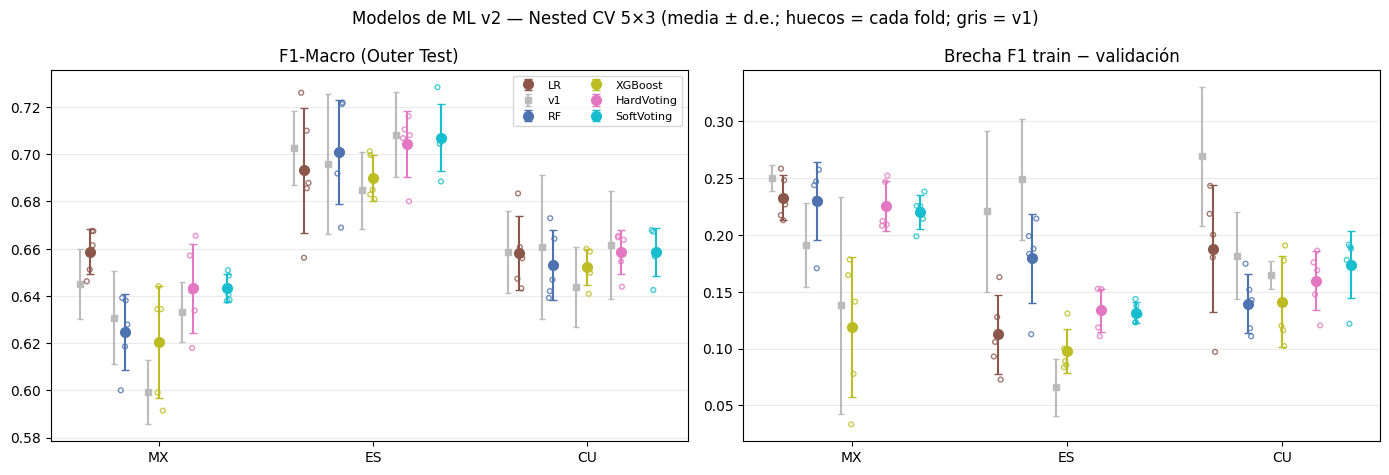

In [14]:
COLOR_ML = {"LR": "#8c564b", "RF": "#4c72b0", "XGBoost": "#bcbd22", "HardVoting": "#e377c2", "SoftVoting": "#17becf"}
PANELES = [("outer_f1_macro", "F1-Macro (Outer Test)"), ("generalization_gap", "Brecha F1 train − validación")]
rng_fig = np.random.default_rng(RANDOM_STATE)
sep = 0.16
v2p = df_outer[df_outer["principal"]].copy()
v2p["modelo"] = v2p["modelo"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), squeeze=False)
for ax, (col, titulo) in zip(axes[0], PANELES):
    for k, modelo in enumerate(ORDEN_MODELOS):
        for j, variante in enumerate(VARIANTES):
            x = j + (k - (len(ORDEN_MODELOS) - 1) / 2) * sep
            vals = v2p.loc[(v2p.variante == variante) & (v2p.modelo == modelo), col].dropna().to_numpy()
            if len(vals):
                ax.scatter(x + rng_fig.uniform(-0.02, 0.02, len(vals)), vals, s=12, facecolors="none",
                           edgecolors=COLOR_ML[modelo], alpha=0.8, zorder=2)
                ax.errorbar(x, vals.mean(), yerr=vals.std(ddof=1) if len(vals) > 1 else 0, fmt="o", ms=7,
                            capsize=3, color=COLOR_ML[modelo], zorder=3, label=modelo if j == 0 else None)
            if df_v1 is not None:
                v1v = df_v1.loc[(df_v1.variante == variante) & (df_v1.modelo == modelo), col].dropna().to_numpy()
                if len(v1v):
                    ax.errorbar(x - 0.05, v1v.mean(), yerr=v1v.std(ddof=1) if len(v1v) > 1 else 0, fmt="s",
                                ms=5, capsize=2, color="#bbbbbb", zorder=1,
                                label="v1" if (j == 0 and k == 0) else None)
    ax.set_xticks(range(len(VARIANTES)), [v.upper() for v in VARIANTES])
    ax.set_title(titulo)
    ax.grid(axis="y", alpha=0.25)
axes[0, 0].legend(fontsize=8, ncol=2, loc="best")
fig.suptitle("Modelos de ML v2 — Nested CV 5×3 (media ± d.e.; huecos = cada fold; gris = v1)", fontsize=12)
fig.tight_layout()
fig.savefig(OUT_DIR / "ml_v2_nested_f1_brecha.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT_DIR / "ml_v2_nested_f1_brecha.pdf", bbox_inches="tight")
display(fig)
plt.close(fig)

### 8.4 Guardar los resultados de desarrollo — sin tocar test

In [15]:
df_outer.to_csv(OUT_DIR / "outer_folds_ml_v2.csv", index=False)
df_resumen.to_csv(OUT_DIR / "resumen_nested_ml_v2.csv", index=False)
df_regla.to_csv(OUT_DIR / "efecto_regla_lr_rf.csv", index=False)
df_candidatos_inner_lr_rf.to_csv(OUT_DIR / "candidatos_inner_lr_rf.csv", index=False)
df_oof.to_csv(OUT_DIR / "predicciones_oof_ml_v2.csv", index=False)
df_oof_resumen.to_csv(OUT_DIR / "resumen_oof_ml_v2.csv", index=False)
df_limites_lr_rf.to_csv(OUT_DIR / "diagnostico_limites_lr_rf.csv", index=False)
df_limites_xgb.to_csv(OUT_DIR / "diagnostico_limites_xgb.csv", index=False)
pd.DataFrame([VERSIONES]).to_csv(OUT_DIR / "versiones_paquetes.csv", index=False)
for variante, studies in nested_studies.items():
    for outer_fold, study in studies.items():
        study.trials_dataframe().to_csv(OUT_DIR / f"optuna_xgb_{variante}_outer{outer_fold}.csv", index=False)

CONFIG_EXPERIMENTO = {
    "version": "v2",
    "modo": MODO,
    "random_state": RANDOM_STATE,
    "variantes": VARIANTES,
    "n_outer": N_OUTER,
    "n_inner": N_INNER,
    "splitter": "StratifiedGroupKFold",
    "group_key": "transitive_normal_stem_lemma_message_exact",
    "group_audit": df_auditoria_grupos.to_dict(orient="records"),
    "grid_lr": GRID_LR,
    "grid_rf": GRID_RF,
    "rf_n_estimators": RF_N_ESTIMATORS,
    "xgb": {"n_trials_nested": N_TRIALS_NESTED, "n_trials_final": N_TRIALS_FINAL,
            "min_df": MIN_DF_XGB, "sublinear_tf": SUBLINEAR_XGB, "limites": LIMITES_XGB},
    "tfidf": {"max_features": MAX_FEATURES_TFIDF, "stop_words": "NLTK spanish", "n_stopwords": len(STOP_WORDS)},
    "rasgos_linguisticos": "StandardScaler",
    "regla": {"tolerancia": REGLA_TOLERANCIA, "principal": SELECCION_PRINCIPAL,
              "regularizador": REGULARIZADOR},
    "voting": {"hard": "mayoria_2_de_3", "soft": "promedio_probabilidades_umbral_0.5"},
    "calibracion": "temperature scaling sobre probabilidades OOF del train (CV final agrupada de 3 folds)",
    "metricas": "F1-Macro, brecha, NLL sin pesos, ECE 10 bins igual masa, Brier",
    "versions": VERSIONES,
}
with open(OUT_DIR / "config_experimento.json", "w", encoding="utf-8") as fh:
    json.dump(CONFIG_EXPERIMENTO, fh, indent=2, default=str, ensure_ascii=False)
print(f"[EXPORT][ML v2] Resultados de desarrollo guardados en {OUT_DIR}")

[EXPORT][ML v2] Resultados de desarrollo guardados en ..\data\resultados_ml_grouped_5x3_grid_v2


## 9. Búsqueda final, modelos finales y temperatura — todo TRAIN, test cerrado

Igual que en la v1, la búsqueda final usa una CV agrupada de **3 folds** sobre todo el train (semilla `RANDOM_STATE`). LR y RF repiten la rejilla y aplican `SELECCION_PRINCIPAL`; XGBoost repite Optuna (50 trials).

**Temperatura (equivalente al diagnóstico 16-bis de la v6).** Con la configuración final de cada modelo se obtienen probabilidades *out-of-fold* sobre esos mismos 3 folds (cada tuit del train predicho por un modelo que no lo vio). Con ellas se ajusta `T` por variante y modelo; el Soft Voting usa el promedio de las tres probabilidades OOF. El test no interviene en ningún paso.

In [16]:
def probas_oof(construir, X, y, splits):
    # Probabilidades out-of-fold de una configuración fija sobre los folds dados.
    p = np.full(len(y), np.nan)
    for a, b in splits:
        est = construir()
        est.fit(X.iloc[a], y.iloc[a])
        p[b] = est.predict_proba(X.iloc[b])[:, 1]
    assert not np.isnan(p).any(), "OOF incompleto"
    return p


monitor_final = Monitor(
    OUT_DIR,
    total=len(VARIANTES) * (len(MODELOS_LR_RF) * len(PREPROCESAMIENTOS) + N_TRIALS_FINAL),
    unidad="Búsquedas GridSearch y trials completados",
)
FINAL = {}
OOF_FINAL = {}
studies_finales = {}
try:
    for variante in VARIANTES:
        X_por_prep, y = cargar_todos_preps(variante, split="train")
        splits_final = crear_splits_final(y, grupos_train(variante), variante)
        for modelo in MODELOS_LR_RF:
            res, _ = buscar_lr_rf_train(X_por_prep, y, modelo, splits_final, monitor=monitor_final, variante=variante)
            sel = res["selecciones"][SELECCION_PRINCIPAL]
            prep, params = res["prep"], sel["params"]
            FINAL[(variante, modelo)] = {
                "prep": prep, "params": params, "estimator": sel["estimator"],
                "f1_cv_final": sel["inner_f1"], "cv_std_final": sel["inner_std"], **describir_tfidf(params),
            }
            OOF_FINAL[(variante, modelo)] = probas_oof(
                lambda: construir_lr_rf(modelo, params), X_por_prep[prep], y, splits_final
            )
        study = estudio_xgb(X_por_prep, y, splits_final, RANDOM_STATE, N_TRIALS_FINAL, monitor_final,
                            f"[{variante.upper()}][XGBoost][Final]")
        studies_finales[variante] = study
        tfidf, params = separar_params_xgb(study.best_params)
        prep = tfidf["preprocessing"]
        construir_xgb = lambda: crear_pipeline_xgb(params, RANDOM_STATE, tfidf["ngramas"], tfidf["min_df"],
                                                   tfidf["sublinear_tf"])
        est = construir_xgb()
        est.fit(X_por_prep[prep], y)
        FINAL[(variante, "XGBoost")] = {
            "prep": prep, "params": params, "estimator": est,
            "f1_cv_final": float(study.best_value),
            "cv_std_final": study.best_trial.user_attrs.get("cv_f1_std", np.nan),
            "best_ngramas": tfidf["ngramas"], "best_min_df": tfidf["min_df"],
            "best_sublinear_tf": tfidf["sublinear_tf"],
        }
        OOF_FINAL[(variante, "XGBoost")] = probas_oof(construir_xgb, X_por_prep[prep], y, splits_final)
        OOF_FINAL[(variante, "SoftVoting")] = np.mean([OOF_FINAL[(variante, m)] for m in MODELOS], axis=0)
        OOF_FINAL[(variante, "_y")] = y.to_numpy()
except KeyboardInterrupt:
    monitor_final.fallar("Búsqueda final interrumpida")
    raise
except Exception as exc:
    monitor_final.registrar(f"ERROR {type(exc).__name__}: {exc}")
    monitor_final.fallar(f"Búsqueda final con error {type(exc).__name__}; consultar monitor.log")
    raise
monitor_final.finalizar("Búsqueda final completada (LR, RF y XGBoost)")

# Temperatura por variante y modelo (solo train).
TEMPERATURAS = {}
for variante in VARIANTES:
    y_oof = OOF_FINAL[(variante, "_y")]
    TEMPERATURAS[variante] = {}
    for modelo in MODELOS + ["SoftVoting"]:
        T, info = ajustar_temperatura(OOF_FINAL[(variante, modelo)], y_oof)
        info["f1_oof"] = float(f1_score(y_oof, pred_desde_proba(OOF_FINAL[(variante, modelo)]), average="macro"))
        TEMPERATURAS[variante][modelo] = info
        print(f"[TS] {variante.upper()} {modelo:<10} T={T:.3f} | NLL {info['nll_oof_antes']:.4f} → "
              f"{info['nll_oof_despues']:.4f} | ECE {info['ece_oof_antes']:.4f} → {info['ece_oof_despues']:.4f}"
              + ("  ⚠ T en el límite de la grilla" if info["en_limite_grilla"] else ""))
(OUT_DIR / "temperaturas_ml_v2.json").write_text(json.dumps(TEMPERATURAS, indent=2), encoding="utf-8")

filas = []
for (variante, modelo), f in FINAL.items():
    filas.append({"variante": variante, "modelo": modelo, "preprocessing": f["prep"],
                  "ngramas": f["best_ngramas"], "min_df": f["best_min_df"], "sublinear_tf": f["best_sublinear_tf"],
                  "best_f1_cv_final": f["f1_cv_final"], "cv_std_final": f["cv_std_final"],
                  "temperatura": TEMPERATURAS[variante][modelo]["T"], "best_params": f["params"]})
df_seleccion_final = pd.DataFrame(filas).sort_values(["variante", "modelo"])
print("\nCONFIGURACIONES FINALES — SIN TEST")
display(df_seleccion_final)
df_seleccion_final.to_csv(OUT_DIR / "seleccion_final_ml_v2.csv", index=False)

pd.concat(
    [pd.DataFrame({"variante": v, "modelo": m, "idx_train_oficial": np.arange(len(p)),
                   "y_true": OOF_FINAL[(v, "_y")], "prob_ironia": p})
     for (v, m), p in OOF_FINAL.items() if m != "_y"],
    ignore_index=True,
).to_csv(OUT_DIR / "probabilidades_oof_final_ml_v2.csv", index=False)

for (variante, modelo), f in FINAL.items():
    joblib.dump(f["estimator"], MODELS_DIR / f"{modelo.lower()}_{variante}_{f['prep']}.pkl")
for variante, study in studies_finales.items():
    study.trials_dataframe().to_csv(OUT_DIR / f"optuna_xgb_final_{variante}.csv", index=False)
print("Modelos finales entrenados y guardados SOLO con train:", len(FINAL))


✅ [ML v2] Búsqueda final completada (LR, RF y XGBoost) — 2026-10-27 16:48:17
[TS] MX LR         T=0.811 | NLL 0.6134 → 0.6111 | ECE 0.0474 → 0.0345
[TS] MX RF         T=0.524 | NLL 0.6147 → 0.5955 | ECE 0.0897 → 0.0292
[TS] MX XGBoost    T=1.231 | NLL 0.6210 → 0.6182 | ECE 0.0374 → 0.0294
[TS] MX SoftVoting T=0.662 | NLL 0.6030 → 0.5937 | ECE 0.0664 → 0.0228
[TS] ES LR         T=0.748 | NLL 0.5537 → 0.5469 | ECE 0.0538 → 0.0201
[TS] ES RF         T=0.704 | NLL 0.5387 → 0.5280 | ECE 0.0556 → 0.0124
[TS] ES XGBoost    T=0.917 | NLL 0.5471 → 0.5464 | ECE 0.0308 → 0.0271
[TS] ES SoftVoting T=0.683 | NLL 0.5367 → 0.5241 | ECE 0.0588 → 0.0209
[TS] CU LR         T=0.733 | NLL 0.5918 → 0.5861 | ECE 0.0819 → 0.0519
[TS] CU RF         T=0.428 | NLL 0.6082 → 0.5732 | ECE 0.1170 → 0.0223
[TS] CU XGBoost    T=1.025 | NLL 0.6321 → 0.6321 | ECE 0.0509 → 0.0517
[TS] CU SoftVoting T=0.557 | NLL 0.5995 → 0.5809 | ECE 0.0884 → 0.0282

CONFIGURACIONES FINALES — SIN TEST


,variante,modelo,preprocessing,ngramas,min_df,sublinear_tf,best_f1_cv_final,cv_std_final,temperatura,best_params
6,cu,LR,stem,uni_bi,1,True,0.666850,0.011486,0.732955,"{'clf__C': 1.0, 'clf__l1_ratio': 0.0, 'feature..."
7,cu,RF,stem,uni,1,False,0.668451,0.011923,0.427536,"{'clf__max_features': 'sqrt', 'clf__min_sample..."
8,cu,XGBoost,lemma,uni,1,False,0.645461,0.009763,1.025277,"{'n_estimators': 500, 'max_depth': 5, 'learnin..."
3,es,LR,lemma,uni_bi,3,False,0.713634,0.030257,0.748017,"{'clf__C': 1.0, 'clf__l1_ratio': 0.0, 'feature..."
4,es,RF,normal,uni,3,False,0.712034,0.027778,0.703735,"{'clf__max_features': 0.03, 'clf__min_samples_..."
5,es,XGBoost,normal,uni_bi,3,True,0.707673,0.021473,0.916755,"{'n_estimators': 550, 'max_depth': 4, 'learnin..."
0,mx,LR,lemma,uni_bi,2,True,0.649886,0.017676,0.811425,"{'clf__C': 1.0, 'clf__l1_ratio': 0.0, 'feature..."
1,mx,RF,normal,uni_bi,3,False,0.655166,0.029799,0.523979,"{'clf__max_features': 'log2', 'clf__min_sample..."
2,mx,XGBoost,lemma,uni,1,False,0.624312,0.008056,1.231256,"{'n_estimators': 600, 'max_depth': 6, 'learnin..."


Modelos finales entrenados y guardados SOLO con train: 9


## 10. Test oficial — bloqueado

Solo habilitar `EJECUTAR_TEST_OFICIAL=True` y `CONFIRMACION_TEST="TEST_OFICIAL_CONGELADO"` (en `MODO="completo"`) una vez cerrado todo el procedimiento. Esta celda no entrena ni optimiza nada: usa los modelos finales y las temperaturas ya ajustadas con el train.

Para cada variante y modelo (LR, RF, XGBoost, Hard Voting, Soft Voting) se guardan F1-Macro, accuracy, precisión, recall, F1 por clase y, cuando hay probabilidades, **NLL, ECE y Brier antes y después del temperature scaling** (el F1 no cambia con la temperatura). Archivos: `resultados_test_ml_v2.csv` y `predicciones_test_ml_v2.csv` (con `prob_ironia` y `prob_ironia_ts`, para ROC, PR, diagramas de fiabilidad y matrices de confusión en `05_comparacion_final_test`).

In [20]:
EJECUTAR_TEST_OFICIAL=True
CONFIRMACION_TEST="TEST_OFICIAL_CONGELADO"

In [21]:
RESULTADOS_TEST, PREDICCIONES_TEST = [], []

if not EJECUTAR_TEST_OFICIAL:
    print("TEST OFICIAL BLOQUEADO: los modelos y temperaturas se fijaron sin abrir el test.")
else:
    if MODO != "completo":
        raise ValueError("El test oficial requiere MODO='completo'.")
    if CONFIRMACION_TEST != "TEST_OFICIAL_CONGELADO":
        raise ValueError("Bloqueado: confirma explícitamente la evaluación final con CONFIRMACION_TEST.")

    def metricas_test(y, pred, p=None, T=None):
        f1_c = f1_score(y, pred, labels=[0, 1], average=None, zero_division=0)
        fila = {
            "f1_macro_test": f1_score(y, pred, average="macro"),
            "accuracy_test": accuracy_score(y, pred),
            "precision_macro_test": precision_score(y, pred, average="macro", zero_division=0),
            "recall_macro_test": recall_score(y, pred, average="macro", zero_division=0),
            "f1_clase_0": f1_c[0], "f1_clase_1": f1_c[1],
            "nll_test": np.nan, "ece_test": np.nan, "brier_test": np.nan,
            "temperatura": np.nan, "nll_test_ts": np.nan, "ece_test_ts": np.nan, "brier_test_ts": np.nan,
        }
        if p is not None:
            p_T = aplicar_temperatura(p, T)
            fila.update({"nll_test": nll_binaria(p, y), "ece_test": ece_binaria(p, y), "brier_test": brier_binaria(p, y),
                         "temperatura": T, "nll_test_ts": nll_binaria(p_T, y), "ece_test_ts": ece_binaria(p_T, y),
                         "brier_test_ts": brier_binaria(p_T, y)})
        return fila

    ref_cv = df_resumen.set_index(["variante", "modelo"])
    for variante in VARIANTES:
        datos = {}
        for modelo in MODELOS:
            f = FINAL[(variante, modelo)]
            df_test = cargar_split(variante, f["prep"], split="test")
            X_test, y_test = preparar_xy(df_test)
            datos[modelo] = (df_test["ID"].astype(str).reset_index(drop=True), y_test.to_numpy(),
                             f["estimator"].predict_proba(X_test)[:, 1])
        ids, y_ref, _ = datos["LR"]
        for m in MODELOS[1:]:
            assert ids.equals(datos[m][0]) and np.array_equal(y_ref, datos[m][1]), f"Test desalineado: {variante}/{m}"
        P = np.column_stack([datos[m][2] for m in MODELOS])
        salidas = {m: (pred_desde_proba(datos[m][2]), datos[m][2]) for m in MODELOS}
        salidas["HardVoting"] = (((P > 0.5).sum(axis=1) >= 2).astype(int), None)
        salidas["SoftVoting"] = (pred_desde_proba(P.mean(axis=1)), P.mean(axis=1))

        for modelo in ORDEN_MODELOS:
            pred, p = salidas[modelo]
            T = TEMPERATURAS[variante][modelo]["T"] if p is not None else None
            cv = ref_cv.loc[(variante, modelo)]
            RESULTADOS_TEST.append({"variante": variante, "modelo": modelo,
                                    "outer_f1_mean": cv["f1_nested_mean"], "outer_f1_std": cv["f1_nested_std"],
                                    **metricas_test(y_ref, pred, p, T)})
            PREDICCIONES_TEST.append(pd.DataFrame({
                "variante": variante, "modelo": modelo, "ID": ids.to_numpy(), "y_true": y_ref, "y_pred": pred,
                "prob_ironia": p if p is not None else np.nan,
                "prob_ironia_ts": aplicar_temperatura(p, T) if p is not None else np.nan,
            }))
            print(f"{variante.upper()} | {modelo:<10} TEST F1-Macro={RESULTADOS_TEST[-1]['f1_macro_test']:.4f}")

    df_resultados_test = pd.DataFrame(RESULTADOS_TEST)
    display(df_resultados_test.round(4))
    df_resultados_test.to_csv(OUT_DIR / "resultados_test_ml_v2.csv", index=False)
    pd.concat(PREDICCIONES_TEST, ignore_index=True).to_csv(OUT_DIR / "predicciones_test_ml_v2.csv", index=False)
    print("EVALUACIÓN FINAL TERMINADA: no volver a seleccionar hiperparámetros en función del test.")

MX | LR         TEST F1-Macro=0.6850
MX | RF         TEST F1-Macro=0.6700
MX | XGBoost    TEST F1-Macro=0.6507
MX | HardVoting TEST F1-Macro=0.6855
MX | SoftVoting TEST F1-Macro=0.6689
ES | LR         TEST F1-Macro=0.7236
ES | RF         TEST F1-Macro=0.6913
ES | XGBoost    TEST F1-Macro=0.6896
ES | HardVoting TEST F1-Macro=0.7152
ES | SoftVoting TEST F1-Macro=0.7155
CU | LR         TEST F1-Macro=0.6890
CU | RF         TEST F1-Macro=0.6887
CU | XGBoost    TEST F1-Macro=0.6261
CU | HardVoting TEST F1-Macro=0.6949
CU | SoftVoting TEST F1-Macro=0.6878


,variante,modelo,outer_f1_mean,outer_f1_std,f1_macro_test,accuracy_test,precision_macro_test,recall_macro_test,f1_clase_0,f1_clase_1,nll_test,ece_test,brier_test,temperatura,nll_test_ts,ece_test_ts,brier_test_ts
0,mx,LR,0.6587,0.0097,0.6850,0.7200,0.6845,0.6855,0.7900,0.5800,0.5792,0.0809,0.1970,0.8114,0.5695,0.0548,0.1933
1,mx,RF,0.6247,0.0162,0.6700,0.7067,0.6696,0.6704,0.7800,0.5600,0.5994,0.1195,0.2052,0.5240,0.5658,0.0534,0.1924
2,mx,XGBoost,0.6206,0.0237,0.6507,0.6883,0.6498,0.6517,0.7654,0.5360,0.5814,0.0566,0.1990,1.2313,0.5850,0.0745,0.2003
3,mx,HardVoting,0.6433,0.0188,0.6855,0.7233,0.6871,0.6842,0.7946,0.5765,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,mx,SoftVoting,0.6433,0.0060,0.6689,0.7083,0.6701,0.6679,0.7831,0.5547,0.5750,0.0928,0.1948,0.6621,0.5529,0.0537,0.1870
5,es,LR,0.6931,0.0265,0.7236,0.7450,0.7187,0.7337,0.8005,0.6467,0.5375,0.0739,0.1801,0.7480,0.5259,0.0475,0.1768
6,es,RF,0.7008,0.0221,0.6913,0.7167,0.6875,0.6988,0.7798,0.6028,0.5397,0.0507,0.1820,0.7037,0.5293,0.0419,0.1802
7,es,XGBoost,0.6900,0.0097,0.6896,0.7133,0.6857,0.6988,0.7755,0.6037,0.5422,0.0454,0.1832,0.9168,0.5411,0.0391,0.1830
8,es,HardVoting,0.7043,0.0140,0.7152,0.7383,0.7107,0.7238,0.7964,0.6340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,es,SoftVoting,0.7071,0.0142,0.7155,0.7400,0.7113,0.7225,0.7990,0.6321,0.5298,0.0705,0.1772,0.6826,0.5138,0.0457,0.1734


EVALUACIÓN FINAL TERMINADA: no volver a seleccionar hiperparámetros en función del test.


### 10.1 Análisis de errores (solo con el test habilitado)

In [22]:
if not EJECUTAR_TEST_OFICIAL:
    print("Análisis de errores no disponible: test oficial bloqueado.")
else:
    for g in PREDICCIONES_TEST:
        variante, modelo = g["variante"].iloc[0], g["modelo"].iloc[0]
        print(f"\n{'=' * 60}\n{variante.upper()} / {modelo}")
        print(classification_report(g.y_true, g.y_pred, digits=4, zero_division=0))
        print("Matriz de confusión:\n", confusion_matrix(g.y_true, g.y_pred))


MX / LR
              precision    recall  f1-score   support

           0     0.7920    0.7880    0.7900       401
           1     0.5771    0.5829    0.5800       199

    accuracy                         0.7200       600
   macro avg     0.6845    0.6855    0.6850       600
weighted avg     0.7207    0.7200    0.7204       600

Matriz de confusión:
 [[316  85]
 [ 83 116]]

MX / RF
              precision    recall  f1-score   support

           0     0.7820    0.7781    0.7800       401
           1     0.5572    0.5628    0.5600       199

    accuracy                         0.7067       600
   macro avg     0.6696    0.6704    0.6700       600
weighted avg     0.7074    0.7067    0.7070       600

Matriz de confusión:
 [[312  89]
 [ 87 112]]

MX / XGBoost
              precision    recall  f1-score   support

           0     0.7702    0.7606    0.7654       401
           1     0.5294    0.5427    0.5360       199

    accuracy                         0.6883       600
   mac

## 11. Contribución de las variables lingüísticas (exploratorio)

Con los modelos finales (solo train). En LR se reporta |coeficiente|; al estar los rasgos **estandarizados**, ahora sí son comparables **entre los nueve rasgos** (en la v1 no lo eran). En RF y XGBoost se usa `feature_importances_`. No compares la magnitud de un coeficiente de LR con una importancia de RF/XGBoost: son medidas distintas.

In [23]:
filas = []
for (variante, modelo), f in FINAL.items():
    est = f["estimator"]
    clf = est.named_steps["xgb" if modelo == "XGBoost" else "clf"]
    imp = np.asarray(clf.feature_importances_) if hasattr(clf, "feature_importances_") else np.abs(clf.coef_[0])
    n_tfidf = len(est.named_steps["features"].named_transformers_["tfidf"].get_feature_names_out())
    ling = imp[n_tfidf : n_tfidf + len(FEATURE_COLS)]
    if len(ling) == len(FEATURE_COLS):
        filas += [{"variante": variante, "modelo": modelo, "caracteristica": c, "importancia": float(v)}
                  for c, v in zip(FEATURE_COLS, ling)]
df_importancias = pd.DataFrame(filas)
display(df_importancias.pivot_table(index="caracteristica", columns=["variante", "modelo"], values="importancia").round(4))
df_importancias.to_csv(OUT_DIR / "importancias_linguisticas_ml_v2.csv", index=False)

variante            cu                      es                      mx  \
modelo              LR      RF XGBoost      LR      RF XGBoost      LR   
caracteristica                                                           
n_com           0.3840  0.0120  0.0074  0.2049  0.0143  0.0099  0.1087   
n_elo           0.5112  0.0818  0.0202  0.0980  0.0090  0.0088  0.0787   
n_emo           0.0000  0.0000  0.0000  0.0827  0.0070  0.0048  0.1939   
n_exc           0.1774  0.0386  0.0155  0.0730  0.0063  0.0036  0.1280   
n_int           0.0377  0.0167  0.0071  0.0330  0.0069  0.0052  0.0294   
n_may           0.0575  0.0240  0.0081  0.1184  0.0076  0.0039  0.1055   
n_neg           0.1309  0.0070  0.0049  0.2453  0.0167  0.0071  0.2064   
n_pun           0.1226  0.0017  0.0000  0.2168  0.0058  0.0053  0.1255   
n_ris           0.1172  0.0017  0.0040  0.0042  0.0001  0.0000  0.0644   

variante                        
modelo              RF XGBoost  
caracteristica                  
n_com           0.0035  0.0045  
n_elo           0.0194  0.0101  
n_emo           0.0143  0.0066  
n_exc           0.0071  0.0041  
n_int           0.0028  0.0032  
n_may           0.0040  0.0034  
n_neg           0.0102  0.0044  
n_pun           0.0080  0.0054  
n_ris           0.0006  0.0029

## 12. Resumen metodológico y referencias

1. Mismos datos, grupos, semillas y folds que la v1 y que los Transformers (Nested CV 5×3 agrupada con `StratifiedGroupKFold`).
2. **LR y RF siguen con `GridSearchCV`**, con rejillas más finas y centradas en los hiperparámetros que más importan (`C` en LR; `max_features` y `min_samples_leaf` en RF). XGBoost sigue con Optuna TPE.
3. Las opciones de TF-IDF que regularizan (`min_df`, `sublinear_tf`) entran en la búsqueda. Los rasgos lingüísticos se estandarizan dentro de cada fold.
4. **Regla de selección fijada de antemano** (la misma de los pilotos de los Transformers): la regularización más fuerte a ≤ 0.01 del mejor F1 interno. Se reportan las dos selecciones (`max` y `regla`).
5. Métricas iguales a la v6: F1-Macro, brecha, NLL sin pesos, ECE con bins de igual masa y Brier.
6. Hard Voting (mayoría) y Soft Voting (promedio de probabilidades), con reglas fijas.
7. Temperature scaling ajustado solo con probabilidades OOF del train y aplicado al test.
8. El test oficial permanece bloqueado hasta la evaluación final.

**Referencias (revisadas por pares)**

- Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305.
- Bischl, B., et al. (2023). Hyperparameter optimization: Foundations, algorithms, best practices, and open challenges. *WIREs Data Mining and Knowledge Discovery, 13*(2), e1484.
- Breiman, L., Friedman, J. H., Olshen, R. A., & Stone, C. J. (1984). *Classification and Regression Trees*. Wadsworth. (regla de un error estándar)
- Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. *Proceedings of ICML*, PMLR 70, 1321–1330.
- Niculescu-Mizil, A., & Caruana, R. (2005). Predicting good probabilities with supervised learning. *Proceedings of ICML*, 625–632.
- Probst, P., & Boulesteix, A.-L. (2018). To tune or not to tune the number of trees in random forest. *Journal of Machine Learning Research, 18*(181), 1–18.
- Probst, P., Boulesteix, A.-L., & Bischl, B. (2019). Tunability: Importance of hyperparameters of machine learning algorithms. *Journal of Machine Learning Research, 20*(53), 1–32.
- Probst, P., Wright, M. N., & Boulesteix, A.-L. (2019). Hyperparameters and tuning strategies for random forest. *WIREs Data Mining and Knowledge Discovery, 9*(3), e1301.